# **scada-E1-experiment — E1: data efficiency (does the training-free TabPFN density hold its accuracy on short records of normal operation?)**

Implements `E1-experiment.md` (Oct 25, 2026). It answers **RQ2** of the paper: when a plant has only a short record of normal operation, does the training-free TabPFN density hold its accuracy better than detectors fitted or trained from scratch?

**Primary hypothesis** (already written into the paper; do not change it after seeing results): the loss in pAUC between the full FIT split and a 6-hour budget is smaller for TabPFN than for TranAD and for GDN.

**What stays fixed.** Only the data used for fitting changes. SWaT, WADI 2019 (A2) and HAI 21.03; the same CAL and TEST rows as the main experiment; the same cleaned tag set and the same three views, computed on the full recordings with causal 600 s and 60 s windows and then cut to the budget (the detrend view of the first rows of a budget therefore uses up to 10 minutes of earlier data); the same fusion, robust z-score and 99th-percentile CAL threshold, recomputed on CAL for every fitted model. The tag list is **not** recomputed per budget (in a 1-hour window many tags look constant, and dropping them would change the input rather than the estimator).

**Budgets and replicates.** 1 h, 6 h, 24 h and 72 h of normal data plus the full FIT split. Contiguous windows from the end of FIT, just before the one-hour gap: three non-overlapping replicates going backwards from the gap (replicate 0 is the most recent) for 1 h, 6 h and 24 h, one for 72 h, and the full FIT split.

| budget | SWaT (FIT 92 h) | WADI-19 (148 h) | HAI (167 h) |
|---|---|---|---|
| 1 h, 6 h, 24 h | 3 replicates | 3 | 3 |
| 72 h | 1 | 1 | 1 |
| full FIT | 1 run | 1 run | 1 run |

**What is refitted on every budget.** TabPFN (context = all budget rows if fewer than 5,000, else a time-stratified sample of 5,000; one seed, four permutations); GMM (BIC over K in {4, ..., 128}, K <= floor(n / (10 d)), minimum 1, ridge 1e-4); PCA (95% explained variance); Isolation Forest (300 trees, max_samples = min(256, n), three seeds); GDN and TranAD (trained on the budget on the 10 s grid, same maximum epochs, early stopping on the last 10% of the budget, batch size min(default, n/4), three seeds); the two untrained baselines Input norm and Random AE (standardisation statistics from the budget, nothing else changes). A feature that is constant inside a budget gets standard deviation 1 (it is left unscaled), and the number of such features is logged per run.

**Statistics.** Per run: pAUC (FPR <= 10%, McClish-standardised), ROC-AUC, attacks found and realised test FPR at the CAL threshold. One paired event bootstrap (1,000 replicates, one fixed seed; the same resamples of attacks and normal hours for every detector, budget and replicate; the pAUC of the replicate windows are averaged inside each draw). **Primary test**, for each dataset and each comparison method m in {TranAD, GDN}:

$$D_m = \left[\mathrm{pAUC}_{\text{full}} - \mathrm{pAUC}_{6\,\text{h}}\right]_m - \left[\mathrm{pAUC}_{\text{full}} - \mathrm{pAUC}_{6\,\text{h}}\right]_{\text{TabPFN}}$$

supported on a dataset when the 95% interval of D excludes zero in TabPFN's favour (D > 0); the count over the three datasets is reported for each comparison. Secondary: the same D at 1 h and 24 h; TabPFN minus each method at each budget; the smallest budget at which TabPFN's interval still includes its full-FIT pAUC; attacks found and FPR per budget.

#### Decisions taken where the specification leaves room (read before running)
1. **Classical detectors fit on every 20th row of the budget window** (`fit_stride = 20`), as the main experiment does with FIT. This is what makes "a 1-hour GMM with K = 1" happen (180 rows, cap = floor(180 / (10 d)) = 0). The scaler (and TabPFN's context) use all budget rows.
2. **The full-FIT row uses the main-experiment GMM settings** (no cap; grid 4..32 on SWaT and 4..128 on WADI and HAI), so that it reproduces the main table (check in section 7). Set `E1["gmm"]["cap_at_full"] = True` to apply the cap there too (WADI's state view would then be limited to K = 49).
3. **TabPFN uses seed 42 for every replicate** (the replicate windows take the role of seeds). The **full-FIT TabPFN scores are reused from `Scada-context-size-ablation-v1`** (static, N = 5,000, seed 42, one estimator, four permutations, the same context and scaler), which saves about 3 GPU hours and is the single-seed reference the specification asks for. Set `REUSE_ABLATION_FULL_TABPFN = False` to recompute them.
4. **Windows are taken by index on the FIT rows** (`fit_pos`), so a window has exactly the budget's number of rows; FIT contains no attack or guard rows (guard rows are removed before FIT is defined), and on HAI the warm-up rows of each training file are already absent, so a window may jump over them (the number of jumps is logged).
5. **GDN and TranAD windows** reach back at most 100 s before a scored row and may therefore read data from before the budget start, as the views do. Their min-max scaling is computed on the budget rows.
6. The jobs run in the priority order of the specification: 6 h on all datasets, then the full-FIT reference (needed by the primary test), then 1 h, 24 h and 72 h.

#### Estimated running time
The notebook prints the table in section 3 from the live dataset sizes and compares it with the real times at the end. **About 30 GPU hours in total**, almost all of it TabPFN scoring (10 budget runs per dataset; 0.5 h for SWaT, 0.8 h for WADI and 1.7 h for HAI per run, measured in the ablation): roughly 5 h on SWaT, 8 h on WADI and 17 h on HAI. GMM, PCA, Isolation Forest and the untrained baselines take minutes; GDN and TranAD about 15 minutes per dataset; the bootstrap about 30 minutes; the three data sets load in about a minute. **Expect 31 to 33 hours (about 1.4 days)**; 3 hours more if the full-FIT TabPFN scores are recomputed. The run is **resumable** (one cache file per dataset, method, budget and replicate) and `E1["max_hours"]` stops it cleanly after a compute budget. Setting `RUN_TABPFN = False` runs everything else in about two hours.

Outputs, in `results/scada-E1-experiment/`: `E1_summary.csv` (one row per dataset, method, budget and replicate), `E1_paired.csv` (one row per dataset, budget and comparison), the per-run CAL/TEST score files in `scores/<fingerprint>/`, and `output-figures/E1_fig7_pauc_vs_budget_E1.png`.

## **0. Setup, configuration and versioning**

In [1]:
import gc
import hashlib
import importlib.metadata as importlib_metadata
import json
import math
import os
import platform
import random
import time
import warnings
from datetime import datetime
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch import nn
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import tabpfn
from tabpfn import TabPFNClassifier, TabPFNRegressor
from tabpfn_extensions.unsupervised import TabPFNUnsupervisedModel
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("tabpfn", tabpfn.__version__, "| torch", torch.__version__)

Device: cuda (NVIDIA GB10)
tabpfn 9.2.0 | torch 2.12.0+cu130


### **0.1 Configuration**

`DATASETS[...]["teacher"]` are the split / feature settings of the full-pipeline notebooks (copied from `Scada-context-size-ablation-v1`: same FIT / CAL / TEST rows, same tags, same views). `E1` holds everything specific to this experiment. Everything that changes a score enters the cache fingerprint, so a changed setting never silently reuses old scores.

In [2]:
RUN_ID = "scada-E1-experiment"
FIG_VERSION = "E1"
FIG_DPI = 300
SMOKE_TEST = False              # True: tiny run to check the code path (SWaT only, 1 h budget, 500-row contexts, 2 epochs)
RUN_TABPFN = True               # False: every detector except TabPFN (about two hours); TabPFN can be added later, the cache is per job
REUSE_ABLATION_FULL_TABPFN = True   # full-FIT TabPFN = the static N=5000 run of Scada-context-size-ablation-v1 (same seed, context, config)

RESULTS_ROOT = Path("results")
FIG_DIR = Path("output-figures")
ABLATION_DIR = RESULTS_ROOT / "Scada-context-size-ablation-v1"

load_dotenv("/home/jaume/_DEVELOPMENT/_projects/secrets.env")   # adjust the path to where the file is
if RUN_TABPFN:
    assert os.environ.get("TABPFN_TOKEN"), "TABPFN_TOKEN not found in secrets.env"

DATASETS = {
    "SWaT": {"kind": "swat", "path": Path("scada-data/SWaT-A1-A2/clean"), "reference": "SWaT_A1A2-baselines",
             "teacher": {'dataset': 'SWaT 2015 (A1/A2): SWaT_Dataset_Normal_v1 + SWaT_Dataset_Attack_v0',
                            'drop_warmup': True,
                            'fit_fraction': 0.7,
                            'fit_cal_gap_rows': 3600,
                            'post_attack_guard_steps': 30,
                            'cal_stride': 10,
                            'test_stride': 10,
                            'exclude_prefixes': ['AIT'],
                            'include_actuators': True,
                            'detrend_window_s': 600,
                            'dynamics_window_s': 60,
                            'views': ['state', 'detrend', 'dynamics']}},
    "WADI-19": {"kind": "wadi", "path": Path("scada-data/WaDI/WaDi/WADI.A2_19-Nov-2019/clean"), "reference": "WADI_A2_2019-baselines",
                "teacher": {'dataset': 'WADI A2 (19 Nov 2019): clean v2 (timestamps rebuilt from Row)',
                             'drop_warmup': True,
                             'fit_fraction': 0.7,
                             'fit_cal_gap_rows': 3600,
                             'post_attack_guard_steps': 30,
                             'cal_stride': 10,
                             'test_stride': 10,
                             'setpoint_tags': ['TOTAL_CONS_REQUIRED_FLOW'],
                             'exclude_types': ['AIT'],
                             'max_mode_share': 0.99,
                             'actuator_exclude_types': ['LS', 'AIT'],
                             'include_actuators': True,
                             'dedup_spearman': 0.98,
                             'detrend_window_s': 600,
                             'dynamics_window_s': 60,
                             'views': ['state', 'detrend', 'dynamics']}},
    "HAI": {"kind": "hai", "path": Path("scada-data/HAI-21.03/clean"), "file_prefix": "hai21", "reference": "HAI_baselines_v1",
            "teacher": {'dataset': 'HAI 21.03: eight 1 Hz recordings (train1-3 normal, test1-5 attacks), labels from the official '
                                    '`attack` column',
                         'drop_warmup': True,
                         'fit_fraction': 0.7,
                         'fit_cal_gap_rows': 3600,
                         'post_attack_guard_steps': 30,
                         'cal_stride': 10,
                         'test_stride': 10,
                         'setpoint_tags': [],
                         'exclude_types': [],
                         'max_mode_share': 0.99,
                         'actuator_exclude_types': [],
                         'include_actuators': True,
                         'dedup_spearman': 0.98,
                         'detrend_window_s': 600,
                         'dynamics_window_s': 60,
                         'views': ['state', 'detrend', 'dynamics']}},
}

# Per-dataset settings of the main baselines notebooks: GDN's top-k neighbours, and the GMM grid of the full-FIT (main-experiment) run.
DATASETS["SWaT"].update({"gdn_topk": 15, "gmm_full_grid": [4, 8, 16, 32]})
DATASETS["WADI-19"].update({"gdn_topk": 30, "gmm_full_grid": [4, 8, 16, 32, 48, 64, 96, 128]})
DATASETS["HAI"].update({"gdn_topk": 30, "gmm_full_grid": [4, 8, 16, 32, 48, 64, 96, 128]})

E1 = {
    "budgets_h": [1, 6, 24, 72],
    "reps": {1: 3, 6: 3, 24: 3, 72: 1},          # non-overlapping windows going backwards from the gap; 3 x 24 h + 72 h fit in the shortest FIT (92 h)
    "primary_budget_h": 6,
    "views": ["state", "detrend", "dynamics"],
    "families": ["GMM", "PCA", "IF", "Input", "RandAE", "GDN", "TranAD", "TabPFN"],     # cheap ones first
    "primary_comparisons": ["TranAD", "GDN"],     # the hypothesis
    "loss_diff_methods": ["TranAD", "GDN", "GMM", "PCA"],
    "untrained": ["Input", "RandAE"],             # horizontal references in Fig. 7
    "seed": 42,
    "tabpfn": {"max_context": 5000, "n_estimators": 1, "n_permutations": 4, "batch_size": 4096},
    "gmm": {"k_grid": [4, 8, 16, 32, 48, 64, 96, 128], "reg_covar": 1e-4, "max_iter": 100, "seed": 42, "fit_stride": 20,
            "rows_per_param": 10, "cap_at_full": False},
    "if": {"n_estimators": 300, "max_samples": 256, "fit_stride": 20, "seeds": [42, 43, 44]},
    "pca": {"explained_variance": 0.95, "fit_stride": 20},
    "deep": {"grid_s": 10, "train_stride_s": 10, "val_fraction": 0.10, "seeds": [42, 43, 44]},
    "gdn": {"window": 5, "embed_dim": 64, "out_layers": 1, "out_hidden": 128, "dropout": 0.2, "optimizer": "adam", "lr": 1e-3,
            "weight_decay": 0.0, "batch_size": 128, "max_epochs": 50, "patience": 10, "smooth_steps": 4, "err_eps": 1e-2},
    "tranad": {"window": 10, "ff_dim": 16, "dropout": 0.1, "optimizer": "adamw", "lr": 1e-3, "weight_decay": 1e-5, "lr_step": 5,
               "lr_gamma": 0.9, "batch_size": 128, "max_epochs": 20, "patience": 4},
    "target_fpr": 0.01,
    "pauc_max_fpr": 0.10,
    "bootstrap_repeats": 1000,
    "bootstrap_block_rows": 360,                  # 360 rows x 10 s = 1 h
    "bootstrap_seed": 2026,
    "max_hours": None,                            # stop cleanly after this many hours of compute; re-run to resume
}

if SMOKE_TEST:
    RUN_ID += "-smoke"
    FIG_VERSION += "-smoke"
    DATASETS = {"SWaT": DATASETS["SWaT"]}
    E1.update({"budgets_h": [1], "reps": {1: 1}, "primary_budget_h": 1, "bootstrap_repeats": 20, "bootstrap_block_rows": 30})
    E1["tabpfn"].update({"max_context": 500, "n_permutations": 1, "batch_size": 1024})
    E1["gmm"]["k_grid"] = [4, 8]
    E1["if"].update({"n_estimators": 50, "seeds": [42]})
    E1["deep"].update({"seeds": [42], "train_stride_s": 60})
    E1["gdn"]["max_epochs"] = 2
    E1["tranad"]["max_epochs"] = 2
    REUSE_ABLATION_FULL_TABPFN = False
    for cfg in DATASETS.values():
        cfg["gmm_full_grid"] = [4, 8]
        cfg["teacher"].update({"cal_stride": 120, "test_stride": 120})
STRIDE_S = {name: cfg["teacher"]["test_stride"] for name, cfg in DATASETS.items()}
assert all(cfg["teacher"]["cal_stride"] == cfg["teacher"]["test_stride"] for cfg in DATASETS.values())


def fingerprint(obj):
    return hashlib.sha1(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:10]


# A budget / replicate does not change how a run is scored, so the budget lists and the bootstrap are not part of the fingerprint.
SCORE_FP = fingerprint({"teacher": {k: v["teacher"] for k, v in DATASETS.items()}, "gdn_topk": {k: v["gdn_topk"] for k, v in DATASETS.items()},
                        "gmm_full_grid": {k: v["gmm_full_grid"] for k, v in DATASETS.items()},
                        **{k: E1[k] for k in ["views", "seed", "tabpfn", "gmm", "if", "pca", "deep", "gdn", "tranad", "target_fpr"]}})
RUN_DIR = RESULTS_ROOT / RUN_ID
SCORE_DIR = RUN_DIR / "scores" / SCORE_FP
for d in [RUN_DIR, SCORE_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def package_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed"


ENVIRONMENT = {"python": platform.python_version(), "device": DEVICE, "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
               "tabpfn": tabpfn.__version__, "tabpfn_extensions": package_version("tabpfn-extensions"), "torch": torch.__version__,
               "scikit-learn": package_version("scikit-learn"), "pandas": pd.__version__, "numpy": np.__version__}
(RUN_DIR / "config.json").write_text(json.dumps({"run_id": RUN_ID, "score_fingerprint": SCORE_FP, "e1": E1,
                                                 "reuse_ablation_full_tabpfn": REUSE_ABLATION_FULL_TABPFN, "run_tabpfn": RUN_TABPFN,
                                                 "datasets": {k: {"teacher": v["teacher"]} for k, v in DATASETS.items()},
                                                 "environment": ENVIRONMENT, "written": datetime.now().isoformat(timespec="seconds")},
                                                indent=2, default=str))
print(f"RUN_ID {RUN_ID} | score fingerprint {SCORE_FP} -> {SCORE_DIR}")

RUN_ID scada-E1-experiment | score fingerprint 7ec7d38d80 -> results/scada-E1-experiment/scores/7ec7d38d80


### **0.2 Shared helpers**

The evaluation helpers (post-attack guard, event matching, event bootstrap units, robust z-score, the density-compatible TabPFN regressor) are copied unchanged from `Scada-context-size-ablation-v1`, and `curve_metrics` from the baselines notebooks (checked against scikit-learn below). New: `pauc_only` (the same pAUC from one sort, used 100,000 times in the bootstrap), the TabPFN scorer that also times `fit` and scoring, and the budget-aware GMM fit.

In [18]:
def post_attack_guard_mask(is_attack, guard_steps):
    # True = keep. Drops attack rows and the `guard_steps` rows right after each attack.
    is_attack = np.asarray(is_attack).astype(bool)
    keep = ~is_attack
    first_after_attack = np.flatnonzero(is_attack[:-1] & ~is_attack[1:]) + 1
    for start in first_after_attack:
        keep[start:start + guard_steps] = False
    return keep


def threshold_from_calibration(cal_scores, fpr):
    cal_scores = np.asarray(cal_scores)
    return float(np.quantile(cal_scores[np.isfinite(cal_scores)], 1.0 - fpr))


def contiguous_runs(mask):
    # Half-open (start, stop) index pairs of consecutive True values.
    padded = np.concatenate([[0], np.asarray(mask, dtype=np.int8), [0]])
    edges = np.diff(padded)
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def event_metrics(timestamps, y, pred, segments):
    ts = pd.DatetimeIndex(timestamps)
    y = np.asarray(y).astype(bool)
    pred = np.asarray(pred).astype(bool)
    per_event = []
    for seg in segments.itertuples(index=False):
        lo = ts.searchsorted(seg.start, side="left")
        hi = ts.searchsorted(seg.end, side="right")
        hits = np.flatnonzero(pred[lo:hi])
        detected = hits.size > 0
        per_event.append({
            "segment": seg.segment,
            "attack_id": seg.attack_id,
            "attack_point": seg.attack_point,
            "start": seg.start,
            "duration_s": seg.duration_s,
            "test_rows": hi - lo,
            "detected": detected,
            "time_to_detect_s": (ts[lo + hits[0]] - seg.start).total_seconds() if detected else np.nan,
            "fraction_alarmed": float(pred[lo:hi].mean()) if hi > lo else np.nan,
        })
    per_event = pd.DataFrame(per_event)

    alarm_runs = contiguous_runs(pred)
    true_runs = sum(bool(y[a:b].any()) for a, b in alarm_runs)
    tp = int((pred & y).sum())
    point_precision = tp / pred.sum() if pred.sum() else 0.0
    event_recall = float(per_event["detected"].mean())
    summary = {
        "attacks_detected": int(per_event["detected"].sum()),
        "attacks_total": len(per_event),
        "event_recall": event_recall,
        "event_precision": true_runs / len(alarm_runs) if alarm_runs else 0.0,
        "alarm_runs": len(alarm_runs),
        "false_alarm_episodes": len(alarm_runs) - true_runs,
        "composite_f1": (2 * point_precision * event_recall / (point_precision + event_recall)
                         if point_precision + event_recall else 0.0),
        "median_ttd_s": float(per_event["time_to_detect_s"].median()),
    }
    return summary, per_event


def event_bootstrap_indices(attack_units, normal_units, rng):
    # Stratified event bootstrap: resample whole attacks and whole normal blocks, separately.
    pick_a = rng.integers(0, len(attack_units), len(attack_units))
    pick_n = rng.integers(0, len(normal_units), len(normal_units))
    return np.concatenate([attack_units[i] for i in pick_a] + [normal_units[i] for i in pick_n])


def robust_z(values, reference):
    median = np.median(reference)
    iqr = np.subtract(*np.percentile(reference, [75, 25]))
    return (values - median) / (iqr if iqr > 0 else 1.0)


class DensityCompatibleTabPFNRegressor(TabPFNRegressor):
    # Align full-output logits with the density criterion's bin boundaries (as in the pipelines).
    def predict(self, X, **kwargs):
        prediction = super().predict(X, **kwargs)
        if kwargs.get("output_type") == "full":
            borders = prediction["criterion"].borders
            prediction = dict(prediction)
            prediction["logits"] = torch.as_tensor(prediction["logits"]).to(dtype=borders.dtype, device=borders.device)
        return prediction


def finite_anomaly_score(log_density):
    values = np.asarray(log_density, dtype=np.float64)
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return np.zeros_like(values)
    clean = np.nan_to_num(values, nan=finite.min(), neginf=finite.min(), posinf=finite.max())
    return -clean


def time_stratified_context(n_rows, size, seed):
    rng = np.random.default_rng(seed)
    bins = np.array_split(np.arange(n_rows), size)
    return np.array([rng.choice(b) for b in bins if len(b)])


def curve_metrics(y, s, max_fpr):
    # ROC-AUC, McClish-standardised pAUC (FPR <= max_fpr) and average precision from one sort.
    # Same definitions as sklearn's roc_auc_score(max_fpr=...) and average_precision_score.
    y = np.asarray(y).astype(bool)
    order = np.argsort(-np.asarray(s), kind="mergesort")
    s_sorted, y_sorted = np.asarray(s)[order], y[order]
    last = np.r_[np.flatnonzero(np.diff(s_sorted)), len(s_sorted) - 1]
    tps = np.cumsum(y_sorted)[last].astype(np.float64)
    fps = (last + 1) - tps
    tpr, fpr = np.r_[0.0, tps / tps[-1]], np.r_[0.0, fps / fps[-1]]
    auc = np.trapezoid(tpr, fpr)
    stop = np.searchsorted(fpr, max_fpr, side="right")
    part = np.trapezoid(np.r_[tpr[:stop], np.interp(max_fpr, fpr, tpr)], np.r_[fpr[:stop], max_fpr])
    min_area, max_area = 0.5 * max_fpr ** 2, max_fpr
    pauc = 0.5 * (1 + (part - min_area) / (max_area - min_area))
    ap = float(np.sum(np.diff(np.r_[0.0, tps / tps[-1]]) * tps / (tps + fps)))
    return float(auc), float(pauc), ap


def pauc_only(y, s, max_fpr):
    # McClish-standardised partial AUC from one sort: the pAUC half of curve_metrics, without the average precision.
    y = np.asarray(y).astype(bool)
    s = np.asarray(s)
    order = np.argsort(-s, kind="mergesort")
    s_sorted, y_sorted = s[order], y[order]
    last = np.r_[np.flatnonzero(np.diff(s_sorted)), len(s_sorted) - 1]
    tps = np.cumsum(y_sorted)[last].astype(np.float64)
    fps = (last + 1) - tps
    tpr, fpr = np.r_[0.0, tps / tps[-1]], np.r_[0.0, fps / fps[-1]]
    stop = np.searchsorted(fpr, max_fpr, side="right")
    part = np.trapezoid(np.r_[tpr[:stop], np.interp(max_fpr, fpr, tpr)], np.r_[fpr[:stop], max_fpr])
    min_area, max_area = 0.5 * max_fpr ** 2, max_fpr
    return float(0.5 * (1 + (part - min_area) / (max_area - min_area)))


# Sanity check against scikit-learn on random data with ties.
_rng = np.random.default_rng(0)
_y = _rng.random(3000) < 0.1
_s = _rng.normal(size=3000) + 1.2 * _y
_s[::7] = np.round(_s[::7], 1)
assert np.isclose(pauc_only(_y, _s, 0.1), roc_auc_score(_y, _s, max_fpr=0.1)) and np.isclose(curve_metrics(_y, _s, 0.1)[1], pauc_only(_y, _s, 0.1))
print("pauc_only / curve_metrics match scikit-learn.")


def make_teacher(seed):
    kw = dict(n_estimators=E1["tabpfn"]["n_estimators"], device=DEVICE, random_state=seed, memory_saving_mode="auto",
              show_progress_bar=False, ignore_pretraining_limits=True)
    return TabPFNUnsupervisedModel(tabpfn_clf=TabPFNClassifier(**kw), tabpfn_reg=DensityCompatibleTabPFNRegressor(**kw))


def tabpfn_score(X_ctx, X_query, batch_size, seed, numeric_only=False):
    # One fresh model per call: fit on the context, score the query rows in batches (chain-rule density, `n_permutations`).
    # Returns (anomaly score, fit seconds, scoring seconds).
    torch.manual_seed(seed)
    model = make_teacher(seed)
    t0 = time.time()
    model.fit(X_ctx)
    if numeric_only:
        model.categorical_features = []                        # every column goes to the regressor (fallback path only)
    fit_s = time.time() - t0
    chunks, start, t0 = [], 0, time.time()
    while start < len(X_query):
        stop = min(start + batch_size, len(X_query))
        try:
            random.seed(seed)                                  # same chain-rule orders for every batch
            result = model.outliers(torch.as_tensor(X_query[start:stop], dtype=torch.float32),
                                    n_permutations=E1["tabpfn"]["n_permutations"])
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            batch_size = max(256, batch_size // 2)
            print(f"  OOM: query batch halved to {batch_size}")
            continue
        chunks.append(result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result))
        start = stop
    score_s = time.time() - t0
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return finite_anomaly_score(np.concatenate(chunks)), fit_s, score_s


def gmm_candidates(n_rows, d, dataset, is_full):
    # K grid of one fit. Budget windows: K <= floor(n / (10 d)), at least 1. The full-FIT run keeps the main-experiment grid, no cap.
    cfg = E1["gmm"]
    if is_full and not cfg["cap_at_full"]:
        return list(DATASETS[dataset]["gmm_full_grid"])
    cap = max(1, n_rows // (cfg["rows_per_param"] * d))
    return [k for k in cfg["k_grid"] if k <= cap] or [1]


def fit_gmm(X, ks):
    # Full-covariance mixtures, k by BIC. A collapsed component raises the covariance floor and retries.
    cfg = E1["gmm"]
    X = X.astype(np.float64)
    best = None
    for k in ks:
        reg = cfg["reg_covar"]
        for _ in range(4):
            try:
                g = GaussianMixture(k, covariance_type="full", reg_covar=reg, max_iter=cfg["max_iter"], random_state=cfg["seed"]).fit(X)
                break
            except ValueError:
                reg *= 10
        else:
            continue
        bic = g.bic(X)
        if best is None or bic < best[0]:
            best = (bic, k, g)
    return best[2], best[1]

pauc_only / curve_metrics match scikit-learn.


## **1. Datasets: the same split, tags and views as the full-pipeline notebooks**

The three `prepare_*` functions are the load / split / feature-view cells of the three pipelines, wrapped in functions (copied unchanged from `Scada-context-size-ablation-v1`). `build_ds` then keeps, for every stream row, the **raw** (unscaled) view features: every budget fits its own scaler on its own rows. It also keeps the state-view tags on the 10 s grid (causal 10 s rolling median per recording) that GDN and TranAD read.

In [17]:
def prepare_swat(TEACHER_CONFIG, DATA_DIR):
    metadata = json.loads((DATA_DIR / 'swat2015_metadata.json').read_text())
    normal_df = pd.read_csv(DATA_DIR / 'swat2015_normal_clean.csv', parse_dates=['timestamp'])
    attack_df = pd.read_csv(DATA_DIR / 'swat2015_attack_clean.csv', parse_dates=['timestamp'])
    segments = pd.read_csv(DATA_DIR / 'swat2015_label_segments.csv', parse_dates=['start', 'end'])
    attack_list = pd.read_csv(DATA_DIR / 'swat2015_attack_list_clean.csv').dropna(subset=['attack_id'])
    assert normal_df['timestamp'].is_monotonic_increasing and attack_df['timestamp'].is_monotonic_increasing
    assert normal_df['is_attack'].sum() == 0, 'The normal file must be attack-free'
    attack_list['attack_id'] = attack_list['attack_id'].astype(int)
    attack_list['start'] = pd.to_datetime(attack_list['start'], errors='coerce')
    typo = attack_list['start'].dt.year.eq(2015) & attack_list['start'].dt.month.eq(1)
    attack_list.loc[typo, 'start'] = attack_list.loc[typo, 'start'] + pd.DateOffset(years=1)
    attack_list['attack_point'] = attack_list['attack_point'].astype(str).str.split(',').str[0].str.strip()
    mapped_id, mapped_point = ([], [])
    for seg in segments.itertuples(index=False):
        hit = attack_list[attack_list['start'].between(seg.start - pd.Timedelta('120s'), seg.end)]
        mapped_id.append(int(hit['attack_id'].iloc[0]) if len(hit) else -1)
        mapped_point.append(hit['attack_point'].iloc[0] if len(hit) else 'unlisted')
    segments['attack_id'], segments['attack_point'] = (mapped_id, mapped_point)
    print(f'Year-typo rows fixed: {int(typo.sum())} | segments still unmapped: {(segments['attack_id'] == -1).sum()} / {len(segments)}')
    stream = pd.concat([normal_df.assign(source='normal'), attack_df.assign(source='attack')], ignore_index=True)
    stream['is_attack'] = stream['is_attack'].fillna(0).astype(int)
    stream['is_warmup'] = stream['is_warmup'].fillna(0).astype(bool)
    print(f'Normal → attack gap: {attack_df['timestamp'].iloc[0] - normal_df['timestamp'].iloc[-1]}')
    dataset_description = pd.DataFrame([{'file': metadata['source_files'][key], 'role': role, 'start': frame['timestamp'].iloc[0], 'end': frame['timestamp'].iloc[-1], 'days': (frame['timestamp'].iloc[-1] - frame['timestamp'].iloc[0]).total_seconds() / 86400, 'rows_1hz': len(frame), 'attack_rows': int(frame['is_attack'].sum()), 'attack_segments': n_seg} for key, role, frame, n_seg in [('normal', 'normal operation (FIT + CAL)', normal_df, 0), ('attack', 'attack period (TEST)', attack_df, len(segments))]])
    print(f'Tags: {len(metadata['features'])} = {len(metadata['sensors'])} sensors + {len(metadata['actuators'])} actuators')
    assert TEACHER_CONFIG['cal_stride'] == TEACHER_CONFIG['test_stride'], 'adaptive threshold needs equal CAL/TEST strides'
    normal_mask = (stream['source'] == 'normal').to_numpy(copy=True)
    if TEACHER_CONFIG['drop_warmup']:
        normal_mask &= ~stream['is_warmup'].to_numpy()
    normal_pos = np.flatnonzero(normal_mask)
    fit_end = int(TEACHER_CONFIG['fit_fraction'] * len(normal_pos))
    fit_pos = normal_pos[:fit_end]
    cal_pos = normal_pos[fit_end + TEACHER_CONFIG['fit_cal_gap_rows']:]
    guard = TEACHER_CONFIG['post_attack_guard_steps']
    fit_keep = post_attack_guard_mask(stream['is_attack'].to_numpy()[fit_pos], guard)
    cal_keep = post_attack_guard_mask(stream['is_attack'].to_numpy()[cal_pos], guard)
    guard_removed = {'FIT': int((~fit_keep).sum()), 'CAL': int((~cal_keep).sum())}
    fit_pos = fit_pos[fit_keep]
    cal_pos = cal_pos[cal_keep][::TEACHER_CONFIG['cal_stride']]
    test_pos = np.flatnonzero((stream['source'] == 'attack').to_numpy())[::TEACHER_CONFIG['test_stride']]
    print(f'Post-attack guard rows removed: {guard_removed}  (TEST: not applied)')
    print(f'FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {TEACHER_CONFIG['test_stride']} s)')
    SENSORS_USED = [s for s in metadata['sensors'] if not any((s.startswith(p) for p in TEACHER_CONFIG['exclude_prefixes']))]
    EXCLUDED = [s for s in metadata['sensors'] if s not in SENSORS_USED]
    fit_raw = stream.iloc[fit_pos]
    ACTUATORS_ALL = list(metadata['actuators'])
    ACTUATORS_USED = [a for a in ACTUATORS_ALL if fit_raw[a].nunique() > 1] if TEACHER_CONFIG['include_actuators'] else []
    ACTUATORS_CONSTANT = [a for a in ACTUATORS_ALL if fit_raw[a].nunique() <= 1]
    W = TEACHER_CONFIG['detrend_window_s']
    WS = TEACHER_CONFIG['dynamics_window_s']
    DYN_EPS = (0.001 * fit_raw[SENSORS_USED].std() + 1e-09).to_numpy()
    VIEW_FEATURES = {'state': SENSORS_USED + ACTUATORS_USED, 'detrend': [f'{s}_dt{W}' for s in SENSORS_USED], 'dynamics': [f'{s}_sd{WS}' for s in SENSORS_USED]}
    VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in TEACHER_CONFIG['views']}
    ALL_FEATURES = [f for v in VIEW_FEATURES.values() for f in v]

    def build_features(raw):
        sensors = raw[SENSORS_USED].astype(np.float64)
        detrend = sensors - sensors.rolling(W, min_periods=1).mean()
        detrend.columns = [f'{s}_dt{W}' for s in SENSORS_USED]
        dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
        dynamics.columns = [f'{s}_sd{WS}' for s in SENSORS_USED]
        state = pd.concat([sensors, raw[ACTUATORS_USED].astype(np.float64)], axis=1)
        return pd.concat([state, detrend, dynamics], axis=1).astype(np.float32)
    features = build_features(stream)
    derived = [c for c in features.columns if c not in stream.columns]
    stream = pd.concat([stream, features[derived]], axis=1)
    fit_df = stream.iloc[fit_pos].reset_index(drop=True)
    cal_df = stream.iloc[cal_pos].reset_index(drop=True)
    test_df = stream.iloc[test_pos].reset_index(drop=True)
    constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
    assert not constant, f'Constant features in FIT: {constant}'
    assert fit_df['timestamp'].max() < cal_df['timestamp'].min() < test_df['timestamp'].min()
    y_test = test_df['is_attack'].to_numpy().astype(int)
    print(f'Excluded analysers ({len(EXCLUDED)}): {EXCLUDED}')
    print(f'Actuators in the state view ({len(ACTUATORS_USED)}): {ACTUATORS_USED}')
    print(f'Actuators constant in FIT ({len(ACTUATORS_CONSTANT)}): {ACTUATORS_CONSTANT}')
    print({v: len(f) for v, f in VIEW_FEATURES.items()}, 'features per view')
    split_summary = pd.DataFrame([{'split': name, 'start': frame['timestamp'].min(), 'end': frame['timestamp'].max(), 'rows': len(frame), 'stride_s': stride, 'attack_rows': int(frame['is_attack'].sum())} for name, frame, stride in [('FIT', fit_df, 1), ('CAL', cal_df, TEACHER_CONFIG['cal_stride']), ('TEST', test_df, TEACHER_CONFIG['test_stride'])]])
    split_summary['attack_share'] = split_summary['attack_rows'] / split_summary['rows']
    return dict(stream=stream, fit_pos=fit_pos, cal_pos=cal_pos, test_pos=test_pos, fit_df=fit_df, cal_df=cal_df,
                test_df=test_df, VIEW_FEATURES=VIEW_FEATURES, segments=segments, y_test=y_test, split_summary=split_summary)


def prepare_wadi(TEACHER_CONFIG, CLEAN_DIR):
    metadata = json.loads((CLEAN_DIR / 'wadi2019_metadata.json').read_text())
    assert metadata.get('cleaning_version', 1) >= 2, 'Re-run WADI_A2_2019_EDA_and_cleaning.ipynb: the v1 clean files lost the hour.'
    normal_df = pd.read_csv(CLEAN_DIR / 'wadi2019_normal_clean.csv', parse_dates=['timestamp'])
    attack_df = pd.read_csv(CLEAN_DIR / 'wadi2019_attack_clean.csv', parse_dates=['timestamp'], dtype={'attack_id': 'string'})
    segments = pd.read_csv(CLEAN_DIR / 'wadi2019_label_segments.csv', parse_dates=['start', 'end'], dtype={'attack_id': str})
    segments = segments[['segment', 'start', 'end', 'duration_s', 'attack_id', 'attack_point']]
    assert normal_df['timestamp'].is_monotonic_increasing and attack_df['timestamp'].is_monotonic_increasing
    assert normal_df['is_attack'].sum() == 0, 'The normal file must be attack-free'
    SENSORS_ALL = [s for s in metadata['sensors'] if s in normal_df.columns]
    ACTUATORS_ALL = [a for a in metadata['actuators'] if a in normal_df.columns]
    tags = SENSORS_ALL + ACTUATORS_ALL
    missing_cells = {'normal': int(normal_df[tags].isna().sum().sum()), 'attack': int(attack_df[tags].isna().sum().sum())}
    normal_df[tags] = normal_df[tags].ffill().bfill()
    attack_df[tags] = attack_df[tags].ffill().bfill()
    print(f"Cells still missing after the cleaner's {metadata['ffill_limit_s']} s forward-fill (now filled): {missing_cells}")
    print(f'Labelled segments: {len(segments)} | unlisted: {(segments['attack_id'] == 'unlisted').sum()} | listed attacks without labelled rows: {metadata.get('listed_attacks_without_labels')}')
    stream = pd.concat([normal_df.assign(source='normal'), attack_df.assign(source='attack')], ignore_index=True)
    stream['is_warmup'] = stream['is_warmup'].fillna(0).astype(bool)
    gaps = stream['timestamp'].diff().dt.total_seconds().fillna(1.0)
    stream['block'] = (gaps != 1.0).cumsum()
    print(f'Tags: {len(SENSORS_ALL)} sensors + {len(ACTUATORS_ALL)} actuators')
    assert TEACHER_CONFIG['cal_stride'] == TEACHER_CONFIG['test_stride'], 'adaptive threshold needs equal CAL/TEST strides'
    normal_mask = (stream['source'] == 'normal').to_numpy(copy=True)
    if TEACHER_CONFIG['drop_warmup']:
        normal_mask &= ~stream['is_warmup'].to_numpy()
    normal_pos = np.flatnonzero(normal_mask)
    fit_end = int(TEACHER_CONFIG['fit_fraction'] * len(normal_pos))
    fit_pos = normal_pos[:fit_end]
    cal_pos = normal_pos[fit_end + TEACHER_CONFIG['fit_cal_gap_rows']:]
    guard = TEACHER_CONFIG['post_attack_guard_steps']
    fit_keep = post_attack_guard_mask(stream['is_attack'].to_numpy()[fit_pos], guard)
    cal_keep = post_attack_guard_mask(stream['is_attack'].to_numpy()[cal_pos], guard)
    fit_pos = fit_pos[fit_keep]
    cal_pos = cal_pos[cal_keep][::TEACHER_CONFIG['cal_stride']]
    test_pos = np.flatnonzero((stream['source'] == 'attack').to_numpy())[::TEACHER_CONFIG['test_stride']]
    print(f'Post-attack guard rows removed: FIT {int((~fit_keep).sum())}, CAL {int((~cal_keep).sum())} (TEST: not applied)')
    print(f'FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {TEACHER_CONFIG['test_stride']} s)')
    def tag_type(tag):
        parts = tag.split('_')
        return parts[1] if len(parts) > 2 else parts[0]

    def dedup(tags, frame, threshold):
        corr = frame[tags].rank().corr().abs()
        kept = []
        for t in tags:
            if not any((corr.at[t, k] >= threshold for k in kept)):
                kept.append(t)
        return kept
    fit_raw = stream.iloc[fit_pos]
    fit_sample = fit_raw.iloc[::20]
    varies = lambda t: fit_raw[t].nunique() > 1
    SETPOINTS = [s for s in SENSORS_ALL if (s.endswith('_SP') or s in TEACHER_CONFIG['setpoint_tags']) and varies(s)]
    mode_share = lambda t: fit_raw[t].value_counts(normalize=True).iloc[0]
    candidates = [s for s in SENSORS_ALL if s not in SETPOINTS and (not s.endswith('_SP')) and varies(s)]
    EXCLUDED_TYPE = [s for s in candidates if tag_type(s) in TEACHER_CONFIG['exclude_types']]
    NEAR_CONSTANT = [s for s in candidates if s not in EXCLUDED_TYPE and mode_share(s) >= TEACHER_CONFIG['max_mode_share']]
    candidates = [s for s in candidates if s not in EXCLUDED_TYPE and s not in NEAR_CONSTANT]
    CONTINUOUS = dedup(candidates, fit_sample, TEACHER_CONFIG['dedup_spearman'])
    act_candidates = [a for a in ACTUATORS_ALL if varies(a) and tag_type(a) not in TEACHER_CONFIG['actuator_exclude_types']]
    ACTUATORS_USED = dedup(act_candidates, fit_sample, TEACHER_CONFIG['dedup_spearman']) if TEACHER_CONFIG['include_actuators'] else []
    ACTUATORS_CONSTANT = [a for a in ACTUATORS_ALL if not varies(a)]
    W = TEACHER_CONFIG['detrend_window_s']
    WS = TEACHER_CONFIG['dynamics_window_s']
    DYN_EPS = (0.001 * fit_raw[CONTINUOUS].std() + 1e-09).to_numpy()
    VIEW_FEATURES = {'state': CONTINUOUS + SETPOINTS + ACTUATORS_USED, 'detrend': [f'{s}_dt{W}' for s in CONTINUOUS], 'dynamics': [f'{s}_sd{WS}' for s in CONTINUOUS]}
    VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in TEACHER_CONFIG['views']}
    ALL_FEATURES = list(dict.fromkeys((f for v in VIEW_FEATURES.values() for f in v)))

    def build_features(raw):
        sensors = raw[CONTINUOUS].astype(np.float64)
        detrend = sensors - sensors.rolling(W, min_periods=1).mean()
        detrend.columns = [f'{s}_dt{W}' for s in CONTINUOUS]
        dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
        dynamics.columns = [f'{s}_sd{WS}' for s in CONTINUOUS]
        return pd.concat([detrend, dynamics], axis=1).astype(np.float32)
    derived = pd.concat([build_features(block) for _, block in stream.groupby('block', sort=False)])
    stream = pd.concat([stream, derived], axis=1)
    fit_df = stream.iloc[fit_pos].reset_index(drop=True)
    cal_df = stream.iloc[cal_pos].reset_index(drop=True)
    test_df = stream.iloc[test_pos].reset_index(drop=True)
    test_df['attack_id'] = 'normal'
    for seg in segments.itertuples(index=False):
        test_df.loc[test_df['timestamp'].between(seg.start, seg.end), 'attack_id'] = seg.attack_id
    constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
    assert not constant, f'Constant features in FIT: {constant}'
    assert fit_df['timestamp'].max() < cal_df['timestamp'].min() < test_df['timestamp'].min()
    y_test = test_df['is_attack'].to_numpy().astype(int)
    print(f'Set points in the state view ({len(SETPOINTS)}): {SETPOINTS}')
    print(f'Continuous sensors ({len(CONTINUOUS)}), removed as near-duplicates: {[c for c in candidates if c not in CONTINUOUS]}')
    print(f'Excluded by type {TEACHER_CONFIG['exclude_types']}: {EXCLUDED_TYPE}')
    print(f'Near-constant in FIT (mode share ≥ {TEACHER_CONFIG['max_mode_share']}): {NEAR_CONSTANT}')
    print(f'Actuators in the state view ({len(ACTUATORS_USED)}): {ACTUATORS_USED}')
    print(f'Actuators constant in FIT ({len(ACTUATORS_CONSTANT)}): {ACTUATORS_CONSTANT}')
    print({v: len(f) for v, f in VIEW_FEATURES.items()}, 'features per view')
    split_summary = pd.DataFrame([{'split': name, 'start': frame['timestamp'].min(), 'end': frame['timestamp'].max(), 'rows': len(frame), 'stride_s': stride, 'attack_rows': int(frame['is_attack'].sum())} for name, frame, stride in [('FIT', fit_df, 1), ('CAL', cal_df, TEACHER_CONFIG['cal_stride']), ('TEST', test_df, TEACHER_CONFIG['test_stride'])]])
    split_summary['attack_share'] = split_summary['attack_rows'] / split_summary['rows']
    return dict(stream=stream, fit_pos=fit_pos, cal_pos=cal_pos, test_pos=test_pos, fit_df=fit_df, cal_df=cal_df,
                test_df=test_df, VIEW_FEATURES=VIEW_FEATURES, segments=segments, y_test=y_test, split_summary=split_summary)


def prepare_hai(TEACHER_CONFIG, CLEAN_DIR, FILE_PREFIX):
    metadata = json.loads((CLEAN_DIR / f'{FILE_PREFIX}_metadata.json').read_text())
    assert metadata.get('cleaning_version', 1) >= 2, 'Re-run the cleaning notebook: the v2 file format is required.'
    normal_df = pd.read_csv(CLEAN_DIR / f'{FILE_PREFIX}_normal_clean.csv', parse_dates=['timestamp'])
    attack_df = pd.read_csv(CLEAN_DIR / f'{FILE_PREFIX}_attack_clean.csv', parse_dates=['timestamp'], dtype={'attack_id': 'string'})
    segments = pd.read_csv(CLEAN_DIR / f'{FILE_PREFIX}_label_segments.csv', parse_dates=['start', 'end'], dtype={'attack_id': str})
    segments = segments[['segment', 'start', 'end', 'duration_s', 'attack_id', 'attack_point']]
    for df in (normal_df, attack_df):
        assert df.groupby('block_id')['timestamp'].apply(lambda t: t.is_monotonic_increasing).all()
    assert normal_df['is_attack'].sum() == 0, 'The normal files must be attack-free'
    SENSORS_ALL = [s for s in metadata['sensors'] if s in normal_df.columns]
    ACTUATORS_ALL = [a for a in metadata['actuators'] if a in normal_df.columns]
    tags = SENSORS_ALL + ACTUATORS_ALL
    missing_cells = {'normal': int(normal_df[tags].isna().sum().sum()), 'attack': int(attack_df[tags].isna().sum().sum())}
    normal_df[tags] = normal_df.groupby('block_id')[tags].transform(lambda s: s.ffill().bfill())
    attack_df[tags] = attack_df.groupby('block_id')[tags].transform(lambda s: s.ffill().bfill())
    print(f"Cells still missing after the cleaner's {metadata['ffill_limit_s']} s forward-fill (now filled): {missing_cells}")
    print(f'Labelled segments: {len(segments)}')
    stream = pd.concat([normal_df.assign(source='normal'), attack_df.assign(source='attack')], ignore_index=True)
    stream['is_warmup'] = stream['is_warmup'].fillna(0).astype(bool)
    gaps = stream['timestamp'].diff().dt.total_seconds().fillna(1.0)
    stream['block'] = (gaps != 1.0).cumsum()
    print(f'Tags: {len(SENSORS_ALL)} sensors + {len(ACTUATORS_ALL)} discrete')
    assert TEACHER_CONFIG['cal_stride'] == TEACHER_CONFIG['test_stride'], 'adaptive threshold needs equal CAL/TEST strides'
    normal_mask = (stream['source'] == 'normal').to_numpy(copy=True)
    if TEACHER_CONFIG['drop_warmup']:
        normal_mask &= ~stream['is_warmup'].to_numpy()
    normal_pos = np.flatnonzero(normal_mask)
    fit_end = int(TEACHER_CONFIG['fit_fraction'] * len(normal_pos))
    fit_pos = normal_pos[:fit_end]
    cal_pos = normal_pos[fit_end + TEACHER_CONFIG['fit_cal_gap_rows']:]
    guard = TEACHER_CONFIG['post_attack_guard_steps']
    fit_keep = post_attack_guard_mask(stream['is_attack'].to_numpy()[fit_pos], guard)
    cal_keep = post_attack_guard_mask(stream['is_attack'].to_numpy()[cal_pos], guard)
    fit_pos = fit_pos[fit_keep]
    cal_pos = cal_pos[cal_keep][::TEACHER_CONFIG['cal_stride']]
    test_pos = np.flatnonzero((stream['source'] == 'attack').to_numpy())[::TEACHER_CONFIG['test_stride']]
    print(f'Post-attack guard rows removed: FIT {int((~fit_keep).sum())}, CAL {int((~cal_keep).sum())} (TEST: not applied)')
    print(f'FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {TEACHER_CONFIG['test_stride']} s)')
    def tag_type(tag):
        parts = tag.split('_')
        return parts[1] if len(parts) > 2 else parts[0]

    def dedup(tags, frame, threshold):
        corr = frame[tags].rank().corr().abs()
        kept = []
        for t in tags:
            if not any((corr.at[t, k] >= threshold for k in kept)):
                kept.append(t)
        return kept
    fit_raw = stream.iloc[fit_pos]
    fit_sample = fit_raw.iloc[::20]
    varies = lambda t: fit_raw[t].nunique() > 1
    SETPOINTS = [s for s in SENSORS_ALL if (s.endswith('_SP') or s in TEACHER_CONFIG['setpoint_tags']) and varies(s)]
    mode_share = lambda t: fit_raw[t].value_counts(normalize=True).iloc[0]
    candidates = [s for s in SENSORS_ALL if s not in SETPOINTS and (not s.endswith('_SP')) and varies(s)]
    EXCLUDED_TYPE = [s for s in candidates if tag_type(s) in TEACHER_CONFIG['exclude_types']]
    NEAR_CONSTANT = [s for s in candidates if s not in EXCLUDED_TYPE and mode_share(s) >= TEACHER_CONFIG['max_mode_share']]
    candidates = [s for s in candidates if s not in EXCLUDED_TYPE and s not in NEAR_CONSTANT]
    CONTINUOUS = dedup(candidates, fit_sample, TEACHER_CONFIG['dedup_spearman'])
    act_candidates = [a for a in ACTUATORS_ALL if varies(a) and tag_type(a) not in TEACHER_CONFIG['actuator_exclude_types']]
    ACTUATORS_USED = dedup(act_candidates, fit_sample, TEACHER_CONFIG['dedup_spearman']) if TEACHER_CONFIG['include_actuators'] else []
    ACTUATORS_CONSTANT = [a for a in ACTUATORS_ALL if not varies(a)]
    W = TEACHER_CONFIG['detrend_window_s']
    WS = TEACHER_CONFIG['dynamics_window_s']
    DYN_EPS = (0.001 * fit_raw[CONTINUOUS].std() + 1e-09).to_numpy()
    VIEW_FEATURES = {'state': CONTINUOUS + SETPOINTS + ACTUATORS_USED, 'detrend': [f'{s}_dt{W}' for s in CONTINUOUS], 'dynamics': [f'{s}_sd{WS}' for s in CONTINUOUS]}
    VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in TEACHER_CONFIG['views']}
    ALL_FEATURES = list(dict.fromkeys((f for v in VIEW_FEATURES.values() for f in v)))

    def build_features(raw):
        sensors = raw[CONTINUOUS].astype(np.float64)
        detrend = sensors - sensors.rolling(W, min_periods=1).mean()
        detrend.columns = [f'{s}_dt{W}' for s in CONTINUOUS]
        dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
        dynamics.columns = [f'{s}_sd{WS}' for s in CONTINUOUS]
        return pd.concat([detrend, dynamics], axis=1).astype(np.float32)
    derived = pd.concat([build_features(block) for _, block in stream.groupby('block', sort=False)])
    stream = pd.concat([stream, derived], axis=1)
    fit_df = stream.iloc[fit_pos].reset_index(drop=True)
    cal_df = stream.iloc[cal_pos].reset_index(drop=True)
    test_df = stream.iloc[test_pos].reset_index(drop=True)
    test_df['attack_id'] = 'normal'
    for seg in segments.itertuples(index=False):
        test_df.loc[test_df['timestamp'].between(seg.start, seg.end), 'attack_id'] = seg.attack_id
    constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
    assert not constant, f'Constant features in FIT: {constant}'
    assert fit_df['timestamp'].max() < cal_df['timestamp'].min()
    y_test = test_df['is_attack'].to_numpy().astype(int)
    print(f'Set points in the state view ({len(SETPOINTS)}): {SETPOINTS}')
    print(f'Continuous sensors ({len(CONTINUOUS)}), removed as near-duplicates: {[c for c in candidates if c not in CONTINUOUS]}')
    print(f'Excluded by type {TEACHER_CONFIG['exclude_types']}: {EXCLUDED_TYPE}')
    print(f'Near-constant in FIT (mode share ≥ {TEACHER_CONFIG['max_mode_share']}): {NEAR_CONSTANT}')
    print(f'Actuators in the state view ({len(ACTUATORS_USED)}): {ACTUATORS_USED}')
    print(f'Actuators constant in FIT ({len(ACTUATORS_CONSTANT)}): {ACTUATORS_CONSTANT}')
    print({v: len(f) for v, f in VIEW_FEATURES.items()}, 'features per view')
    split_summary = pd.DataFrame([{'split': name, 'start': frame['timestamp'].min(), 'end': frame['timestamp'].max(), 'rows': len(frame), 'stride_s': stride, 'attack_rows': int(frame['is_attack'].sum())} for name, frame, stride in [('FIT', fit_df, 1), ('CAL', cal_df, TEACHER_CONFIG['cal_stride']), ('TEST', test_df, TEACHER_CONFIG['test_stride'])]])
    split_summary['attack_share'] = split_summary['attack_rows'] / split_summary['rows']
    return dict(stream=stream, fit_pos=fit_pos, cal_pos=cal_pos, test_pos=test_pos, fit_df=fit_df, cal_df=cal_df,
                test_df=test_df, VIEW_FEATURES=VIEW_FEATURES, segments=segments, y_test=y_test, split_summary=split_summary)

In [5]:
%%time
PREPARE = {
    "swat": lambda cfg: prepare_swat(cfg["teacher"], cfg["path"]),
    "wadi": lambda cfg: prepare_wadi(cfg["teacher"], cfg["path"]),
    "hai": lambda cfg: prepare_hai(cfg["teacher"], cfg["path"], cfg["file_prefix"]),
}


def build_ds(name):
    cfg = DATASETS[name]
    P = PREPARE[cfg["kind"]](cfg)
    stream, fit_df, cal_df, test_df, VF = P["stream"], P["fit_df"], P["cal_df"], P["test_df"], P["VIEW_FEATURES"]
    views = [v for v in E1["views"] if v in VF]
    if "block" not in stream.columns:
        stream["block"] = 0                      # SWaT: one continuous 1 Hz stream (normal file, 1 s gap, attack file)
    block = stream["block"].to_numpy()
    raw_all = {v: stream[VF[v]].to_numpy(np.float32) for v in views}          # every stream row, unscaled
    # State-view tags on the 10 s grid for GDN / TranAD: causal rolling median per contiguous recording (no window crosses a gap).
    starts = np.flatnonzero(np.r_[True, block[1:] != block[:-1]])
    bounds = np.r_[starts, len(stream)]
    state_vals = stream[VF["state"]].astype(np.float32)
    grid_raw = np.empty((len(stream), len(VF["state"])), np.float32)
    for a, b in zip(bounds[:-1], bounds[1:]):
        grid_raw[a:b] = state_vals.iloc[a:b].rolling(E1["deep"]["grid_s"], min_periods=1).median().to_numpy(np.float32)
    block_start = starts[np.searchsorted(starts, np.arange(len(stream)), side="right") - 1]
    ds = SimpleNamespace(
        name=name, views=views, stride_s=STRIDE_S[name], segments=P["segments"], y_test=P["y_test"],
        test_ts=pd.DatetimeIndex(test_df["timestamp"]), cal_ts=pd.DatetimeIndex(cal_df["timestamp"]),
        fit_pos=P["fit_pos"], cal_pos=P["cal_pos"], test_pos=P["test_pos"], block=block, block_start=block_start,
        is_warmup=stream["is_warmup"].to_numpy().astype(bool), is_attack_stream=stream["is_attack"].to_numpy().astype(bool),
        n_fit=len(fit_df), n_cal=len(cal_df), n_test=len(test_df), n_features={v: len(VF[v]) for v in views},
        raw_all=raw_all, grid_raw=grid_raw, split_summary=P["split_summary"])
    h = hashlib.sha1(ds.cal_pos.tobytes() + ds.test_pos.tobytes())
    for v in views:                                # the CAL and TEST rows and their features, byte for byte
        h.update(raw_all[v][ds.cal_pos].tobytes() + raw_all[v][ds.test_pos].tobytes())
    ds.cal_test_hash = h.hexdigest()[:16]
    del P, stream, state_vals
    gc.collect()
    return ds


DS = {name: build_ds(name) for name in DATASETS}
split_table = pd.concat([d.split_summary.assign(dataset=n) for n, d in DS.items()])[
    ["dataset", "split", "start", "end", "rows", "stride_s", "attack_rows", "attack_share"]]
split_table["hours"] = split_table["rows"] * split_table["stride_s"] / 3600
display(split_table.round(3))
print({n: d.n_features for n, d in DS.items()})
print({n: d.cal_test_hash for n, d in DS.items()}, "<- hash of the CAL and TEST rows (checked against every run in section 7)")
split_table.to_csv(RUN_DIR / "split_summary.csv", index=False)

Year-typo rows fixed: 5 | segments still unmapped: 1 / 35
Normal → attack gap: 0 days 00:00:01
Tags: 51 = 25 sensors + 26 actuators
Post-attack guard rows removed: {'FIT': 0, 'CAL': 0}  (TEST: not applied)
FIT 331,380 rows (1 Hz) | CAL 13,842 | TEST 44,992 (every 10 s)
Excluded analysers (9): ['AIT201', 'AIT202', 'AIT203', 'AIT401', 'AIT402', 'AIT501', 'AIT502', 'AIT503', 'AIT504']
Actuators in the state view (12): ['MV101', 'P101', 'MV201', 'P203', 'P205', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'P602']
Actuators constant in FIT (14): ['P102', 'P201', 'P202', 'P204', 'P206', 'P401', 'P402', 'P403', 'P404', 'UV401', 'P501', 'P502', 'P601', 'P603']
{'state': 28, 'detrend': 16, 'dynamics': 16} features per view
Cells still missing after the cleaner's 5 s forward-fill (now filled): {'normal': 9, 'attack': 0}
Labelled segments: 14 | unlisted: 1 | listed attacks without labelled rows: ['13']
Tags: 69 sensors + 54 actuators
Post-attack guard rows removed: FIT 0, CAL 0 (TEST: not 

,dataset,split,start,end,rows,stride_s,attack_rows,attack_share,hours
0,SWaT,FIT,2015-12-22 22:30:00,2015-12-26 18:32:59,331380,1,0,0.000,92.050
1,SWaT,CAL,2015-12-26 19:33:00,2015-12-28 09:59:50,13842,10,0,0.000,38.450
2,SWaT,TEST,2015-12-28 10:00:00,2016-01-02 14:59:51,44992,10,5468,0.122,124.978
0,WADI-19,FIT,2017-09-26 00:00:00,2017-10-05 05:41:18,534079,1,0,0.000,148.355
1,WADI-19,CAL,2017-10-05 06:41:19,2017-10-07 21:16:09,22530,10,0,0.000,62.583
2,WADI-19,TEST,2017-10-09 18:00:00,2017-10-11 18:00:00,17281,10,997,0.058,48.003
0,HAI,FIT,2020-07-11 06:00:00,2020-08-07 11:35:59,599762,1,0,0.000,166.601
1,HAI,CAL,2020-08-07 12:36:00,2020-08-10 11:00:00,25345,10,0,0.000,70.403
2,HAI,TEST,2020-07-07 15:00:00,2020-07-31 12:29:56,40201,10,887,0.022,111.669


{'SWaT': {'state': 28, 'detrend': 16, 'dynamics': 16}, 'WADI-19': {'state': 54, 'detrend': 35, 'dynamics': 35}, 'HAI': {'state': 48, 'detrend': 47, 'dynamics': 47}}
{'SWaT': 'b868aa8b6f23d199', 'WADI-19': 'e2dff957a547d125', 'HAI': '56033dcd59dc05a1'} <- hash of the CAL and TEST rows (checked against every run in section 7)
CPU times: user 32.4 s, sys: 1.01 s, total: 33.4 s
Wall time: 33.4 s


## **2. Budget windows**

A window is the last `B` rows of FIT (replicate 0), the `B` rows before them (replicate 1), and so on: contiguous, non-overlapping, ending just before the one-hour gap that separates FIT from CAL. FIT already excludes warm-up, attack and post-attack-guard rows, so a window holds exactly `B` rows. The checks of the specification (windows end before the gap, no attack or guard rows, row counts, non-overlap) are asserted here.

In [6]:
def make_windows(ds):
    # (budget, replicate) -> stream positions of the window. "full" is the whole FIT split.
    out, n = {}, len(ds.fit_pos)
    for h in E1["budgets_h"]:
        rows = int(round(h * 3600))
        for r in range(E1["reps"][h]):
            lo, hi = n - (r + 1) * rows, n - r * rows
            if lo < 0:
                print(f"{ds.name}: the {h} h replicate {r} does not fit in FIT ({n:,} rows): skipped")
                continue
            out[(h, r)] = ds.fit_pos[lo:hi]
    out[("full", 0)] = ds.fit_pos
    return out


WINDOWS = {name: make_windows(ds) for name, ds in DS.items()}
rows = []
for name, ds in DS.items():
    taken = {}                                 # per budget: replicates of one budget must not overlap (different budgets end at the same row by design)
    for (h, r), pos in WINDOWS[name].items():
        assert pos.max() <= ds.fit_pos[-1] < ds.cal_pos[0], "a window must end before the gap"
        assert not ds.is_attack_stream[pos].any() and not ds.is_warmup[pos].any(), "no attack, guard or warm-up rows in a window"
        if h != "full":
            assert len(pos) == int(round(h * 3600)), f"{name} {h} h rep {r}: {len(pos)} rows"
            mask = taken.setdefault(h, np.zeros(len(ds.is_attack_stream), bool))
            assert not mask[pos].any(), f"{name} {h} h: replicates overlap"
            mask[pos] = True
        rows.append({"dataset": name, "budget_h": h if h != "full" else ds.n_fit / 3600, "full": h == "full", "rep": r, "rows": len(pos),
                     "first_pos": int(pos[0]), "last_pos": int(pos[-1]), "jumps_over_missing_rows": int((np.diff(pos) > 1).sum()),
                     "stream_rows_between_window_end_and_CAL": int(ds.cal_pos[0] - pos[-1])})
windows_table = pd.DataFrame(rows)
display(windows_table)
print("window checks passed: end before the gap, no attack / guard / warm-up rows, exact row counts, no overlap between replicates")

,dataset,budget_h,full,rep,rows,first_pos,last_pos,jumps_over_missing_rows,stream_rows_between_window_end_and_CAL
0,SWaT,1.000000,False,0,3600,349380,352979,0,3601
1,SWaT,1.000000,False,1,3600,345780,349379,0,7201
2,SWaT,1.000000,False,2,3600,342180,345779,0,10801
3,SWaT,6.000000,False,0,21600,331380,352979,0,3601
4,SWaT,6.000000,False,1,21600,309780,331379,0,25201
5,SWaT,6.000000,False,2,21600,288180,309779,0,46801
6,SWaT,24.000000,False,0,86400,266580,352979,0,3601
7,SWaT,24.000000,False,1,86400,180180,266579,0,90001
8,SWaT,24.000000,False,2,86400,93780,180179,0,176401
9,SWaT,72.000000,False,0,259200,93780,352979,0,3601


window checks passed: end before the gap, no attack / guard / warm-up rows, exact row counts, no overlap between replicates


## **3. Detectors: refit on every budget window**

**Per budget window** a `StandardScaler` is fitted on the window's rows (a feature that is constant in the window gets standard deviation 1 and is counted), CAL and TEST are transformed with it, and every detector sees only the window. The score of a view is the mean over the seeds of the robust z-score against that model's own CAL scores; the views are averaged (the fusion of the main experiment). `GDN` and `TranAD` read the state-view tags on the 10 s grid instead.

| detector | what is refitted on the window |
|---|---|
| TabPFN | context = all window rows if fewer than 5,000, else a time-stratified sample of 5,000; seed 42; four permutations |
| GMM | every 20th window row; BIC over K in {4, ..., 128}, K <= floor(n / (10 d)), min 1; ridge 1e-4 |
| PCA | every 20th window row; 95% explained variance |
| Isolation Forest | every 20th window row; 300 trees, max_samples = min(256, n), 3 seeds |
| GDN, TranAD | trained on the window (one training window per 10 s; 1 h = 360 steps); early stopping on the last 10%; batch size min(default, n/4); 3 seeds |
| Input norm, Random AE | statistics from the window; nothing is trained |

In [7]:
class GDN(nn.Module):
    # Graph Deviation Network (Deng & Hooi, AAAI 2021), dense implementation.
    def __init__(self, n_nodes, window, embed_dim, topk, out_layers, out_hidden, dropout):
        super().__init__()
        self.topk = min(topk, n_nodes - 1)
        self.embedding = nn.Embedding(n_nodes, embed_dim)
        self.lin = nn.Linear(window, embed_dim, bias=False)
        self.att_i, self.att_j = nn.Parameter(torch.empty(embed_dim)), nn.Parameter(torch.empty(embed_dim))
        self.att_em_i, self.att_em_j = nn.Parameter(torch.empty(embed_dim)), nn.Parameter(torch.empty(embed_dim))
        self.gnn_bias = nn.Parameter(torch.zeros(embed_dim))
        self.bn_gnn, self.bn_out = nn.BatchNorm1d(embed_dim), nn.BatchNorm1d(embed_dim)
        self.dropout = nn.Dropout(dropout)
        layers, width = [], embed_dim
        for _ in range(out_layers - 1):
            layers += [nn.Linear(width, out_hidden), nn.BatchNorm1d(out_hidden), nn.ReLU()]
            width = out_hidden
        self.out_mlp = nn.ModuleList(layers)
        self.out_final = nn.Linear(width, 1)
        nn.init.kaiming_uniform_(self.embedding.weight, a=math.sqrt(5))
        nn.init.xavier_uniform_(self.lin.weight)
        for p in (self.att_i, self.att_j, self.att_em_i, self.att_em_j):
            nn.init.normal_(p, std=embed_dim ** -0.5)

    def neighbours(self):
        # Learned graph: each node's top-k cosine neighbours among the node embeddings, plus itself.
        emb = F.normalize(self.embedding.weight.detach(), dim=1)
        cos = emb @ emb.T
        cos.fill_diagonal_(-float("inf"))
        nbr = cos.topk(self.topk, dim=1).indices
        return torch.cat([torch.arange(len(nbr), device=nbr.device)[:, None], nbr], dim=1)

    def forward(self, x):                                  # x: (B, N, window) -> (B, N) forecast
        emb = self.embedding.weight                        # (N, d)
        nbr = self.neighbours()                            # (N, k + 1)
        h = self.lin(x)                                    # (B, N, d)
        g_i = (h * self.att_i).sum(-1) + (emb * self.att_em_i).sum(-1)
        g_j = (h * self.att_j).sum(-1) + (emb * self.att_em_j).sum(-1)
        alpha = F.leaky_relu(g_i[:, :, None] + g_j[:, nbr], 0.2).softmax(dim=-1)   # (B, N, k + 1)
        z = (alpha[..., None] * h[:, nbr]).sum(dim=2) + self.gnn_bias              # (B, N, d)
        z = F.relu(self.bn_gnn(z.transpose(1, 2))).transpose(1, 2)
        out = self.dropout(F.relu(self.bn_out((z * emb).transpose(1, 2))).transpose(1, 2))
        for layer in self.out_mlp:
            out = layer(out.transpose(1, 2)).transpose(1, 2) if isinstance(layer, nn.BatchNorm1d) else layer(out)
        return self.out_final(out).squeeze(-1)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout):
        super().__init__()
        position = torch.arange(max_len)[:, None]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div)
        pe[:, 1::2] = torch.cos(position * div)[:, :d_model // 2]
        self.register_buffer("pe", pe)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                                  # (B, L, d)
        return self.dropout(x + self.pe[:x.size(1)])


class TranAD(nn.Module):
    # TranAD (Tuli et al., VLDB 2022): transformer with two-phase adversarial self-conditioning.
    def __init__(self, n_feats, window, ff_dim, dropout):
        super().__init__()
        d = 2 * n_feats
        self.n_feats = n_feats
        self.pos = PositionalEncoding(d, window, dropout)
        layer = lambda cls: cls(d_model=d, nhead=n_feats, dim_feedforward=ff_dim, dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer(nn.TransformerEncoderLayer), 1, enable_nested_tensor=False)
        self.decoder1 = nn.TransformerDecoder(layer(nn.TransformerDecoderLayer), 1)
        self.decoder2 = nn.TransformerDecoder(layer(nn.TransformerDecoderLayer), 1)
        self.fcn = nn.Sequential(nn.Linear(d, n_feats), nn.Sigmoid())

    def encode(self, src, focus, tgt):
        memory = self.encoder(self.pos(torch.cat([src, focus], dim=-1) * math.sqrt(self.n_feats)))
        return tgt.repeat(1, 1, 2), memory

    def forward(self, src):                                # src: (B, L, F) -> two reconstructions of the last point (B, 1, F)
        tgt = src[:, -1:, :]
        x1 = self.fcn(self.decoder1(*self.encode(src, torch.zeros_like(src), tgt)))
        x2 = self.fcn(self.decoder2(*self.encode(src, (x1 - src) ** 2, tgt)))
        return x1, x2


GRID = E1["deep"]["grid_s"]


class SequenceData:
    # The scaled 10 s grid signal of one dataset on the GPU; windows are gathered per batch from stream positions.
    def __init__(self, signal, block_start):
        self.signal = torch.as_tensor(signal, device=DEVICE)
        self.block_start = torch.as_tensor(block_start, device=DEVICE)
        self.n_features = signal.shape[1]

    def window(self, pos, n_steps, end_offset):
        # (B, n_steps, F) values at pos - GRID*(end_offset + n_steps - 1) ... pos - GRID*end_offset, clamped to the recording start.
        steps = GRID * (torch.arange(n_steps - 1, -1, -1, device=pos.device) + end_offset)
        idx = torch.maximum(pos[:, None] - steps[None, :], self.block_start[pos][:, None])
        return self.signal[idx]

    def target(self, pos):
        return self.signal[pos]


def train_deep(model, train_loss, val_loss, cfg, seed, train_pos, val_pos):
    # Mini-batch training with label-free early stopping on the chronological tail of the budget window.
    gen = torch.Generator().manual_seed(seed)
    opt_cls = torch.optim.AdamW if cfg["optimizer"] == "adamw" else torch.optim.Adam
    opt = opt_cls(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.StepLR(opt, cfg["lr_step"], cfg["lr_gamma"]) if cfg.get("lr_step") else None
    train_t = torch.as_tensor(train_pos, device=DEVICE)
    val_t = torch.as_tensor(val_pos, device=DEVICE)
    bs = max(2, min(cfg["batch_size"], len(train_t) // 4))                      # min(default, n / 4)
    best, best_state, wait, history = np.inf, None, 0, []
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        t0, total, seen = time.time(), 0.0, 0
        perm = train_t[torch.randperm(len(train_t), generator=gen).to(DEVICE)]
        for i in range(0, len(perm), bs):
            batch = perm[i:i + bs]
            if len(batch) < 2:
                continue
            loss = train_loss(model, batch, epoch)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += float(loss) * len(batch)
            seen += len(batch)
        if sched is not None:
            sched.step()
        model.eval()
        with torch.no_grad():
            val = float(np.mean([float(val_loss(model, val_t[i:i + 4096])) for i in range(0, len(val_t), 4096)]))
        history.append({"epoch": epoch, "train_loss": total / max(seen, 1), "val_loss": val, "seconds": time.time() - t0})
        if val < best - 1e-7:
            best, wait = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history)


@torch.no_grad()
def batched(fn, pos, batch=4096):
    pos_t = torch.as_tensor(pos, device=DEVICE)
    return torch.cat([fn(pos_t[i:i + batch]).float().cpu() for i in range(0, len(pos_t), batch)]).numpy()


def run_gdn(data, seed, cfg, pos):
    torch.manual_seed(seed)
    w = cfg["window"]
    model = GDN(data.n_features, w, cfg["embed_dim"], cfg["topk"], cfg["out_layers"], cfg["out_hidden"], cfg["dropout"]).to(DEVICE)
    forecast = lambda m, p: m(data.window(p, w, 1).transpose(1, 2))
    mse = lambda m, p, epoch=None: F.mse_loss(forecast(m, p), data.target(p))
    t0 = time.time()
    model, history = train_deep(model, mse, mse, cfg, seed, pos["train"], pos["val"])
    train_s = time.time() - t0
    err = lambda p: (forecast(model, p) - data.target(p)).abs()
    t0 = time.time()
    err_test = batched(err, pos["test"])
    err_cal = batched(err, pos["cal"])
    score_s = time.time() - t0
    med = np.median(err_cal, axis=0)
    iqr = np.subtract(*np.percentile(err_cal, [75, 25], axis=0))
    smooth = lambda a: pd.Series(a).rolling(cfg["smooth_steps"], min_periods=1).mean().to_numpy()
    score = lambda e: smooth(((e - med) / (iqr + cfg["err_eps"])).max(axis=1))
    return {"cal": score(err_cal), "test": score(err_test), "train_s": train_s, "score_s": score_s}, history


def run_tranad(data, seed, cfg, pos):
    torch.manual_seed(seed)
    L = cfg["window"]
    model = TranAD(data.n_features, L, cfg["ff_dim"], cfg["dropout"]).to(DEVICE)

    def train_loss(m, p, epoch):
        src = data.window(p, L, 0)
        x1, x2 = m(src)
        tgt = src[:, -1:, :]
        return F.mse_loss(x1, tgt) / epoch + (1 - 1 / epoch) * F.mse_loss(x2, tgt)

    def val_loss(m, p):
        src = data.window(p, L, 0)
        return F.mse_loss(m(src)[1], src[:, -1:, :])

    t0 = time.time()
    model, history = train_deep(model, train_loss, val_loss, cfg, seed, pos["train"], pos["val"])
    train_s = time.time() - t0

    def score(p):
        src = data.window(p, L, 0)
        return ((model(src)[1] - src[:, -1:, :]) ** 2).mean(dim=(1, 2))

    t0 = time.time()
    test = batched(score, pos["test"])
    cal = batched(score, pos["cal"])
    return {"cal": cal, "test": test, "train_s": train_s, "score_s": time.time() - t0}, history


# Shape check on random inputs (seconds): forward + backward of both models.
_x = torch.rand(8, 7, E1["gdn"]["window"], device=DEVICE)
_g = GDN(7, E1["gdn"]["window"], 16, 3, 2, 16, 0.1).to(DEVICE)
_g(_x).sum().backward()
_t = TranAD(7, E1["tranad"]["window"], 16, 0.1).to(DEVICE)
sum(o.sum() for o in _t(torch.rand(8, E1["tranad"]["window"], 7, device=DEVICE))).backward()
del _x, _g, _t
print("GDN and TranAD: forward/backward OK")

GDN and TranAD: forward/backward OK


In [19]:
# cell [6]
def prepare_window(ds, win_pos):
    # Scaler fitted on the budget rows only; CAL and TEST transformed with it. A feature that is constant in the window
    # (variance 0) is left unscaled (standard deviation 1; scikit-learn does this) and counted.
    raw = {v: ds.raw_all[v][win_pos] for v in ds.views}
    scalers = {v: StandardScaler().fit(raw[v]) for v in ds.views}
    tf = lambda v, a: scalers[v].transform(a).astype(np.float32)
    return SimpleNamespace(fit={v: tf(v, raw[v]) for v in ds.views},
                           cal={v: tf(v, ds.raw_all[v][ds.cal_pos]) for v in ds.views},
                           test={v: tf(v, ds.raw_all[v][ds.test_pos]) for v in ds.views},
                           n_const={v: int((scalers[v].var_ == 0).sum()) for v in ds.views})


def prepare_sequence(ds, win_pos):
    # State-view tags on the 10 s grid, min-max scaled on the budget rows (a constant tag gets range 1 and is counted).
    lo, hi = ds.grid_raw[win_pos].min(axis=0), ds.grid_raw[win_pos].max(axis=0)
    scaled = ((ds.grid_raw - lo) / np.where(hi > lo, hi - lo, 1.0)).astype(np.float32)
    return SequenceData(scaled, ds.block_start), int((hi <= lo).sum())


def seed_mean_z(per_seed):
    # per_seed: list of {"cal", "test"} raw scores -> mean over seeds of the robust z against each seed's CAL scores.
    return {s: np.mean([robust_z(r[s], r["cal"]) for r in per_seed], axis=0) for s in ("cal", "test")}


def fuse_views(per_view):
    return {s: np.mean([per_view[v][s] for v in per_view], axis=0) for s in ("cal", "test")}


def ablation_full_tabpfn(ds):
    # Full-FIT TabPFN raw scores from the static N=5000 run of the context ablation (same seed, context, scaler and settings).
    cfg_path = ABLATION_DIR / "config.json"
    hits = sorted(ABLATION_DIR.glob(f"scores/*/{ds.name}_TabPFN_N5000_static.npz"), key=lambda p: p.stat().st_mtime)
    if not (REUSE_ABLATION_FULL_TABPFN and hits and cfg_path.exists()):
        return None
    a = json.loads(cfg_path.read_text())["ablation"]
    same = (a["seed"] == E1["seed"] and a["n_estimators"] == E1["tabpfn"]["n_estimators"]
            and a["n_permutations"] == E1["tabpfn"]["n_permutations"] and E1["tabpfn"]["max_context"] == 5000)
    c = dict(np.load(hits[-1], allow_pickle=True))
    if not same or not all(f"test__{v}" in c and len(c[f"cal__{v}"]) == ds.n_cal and len(c[f"test__{v}"]) == ds.n_test for v in ds.views):
        print(f"  {ds.name}: ablation scores found but not compatible: recomputing")
        return None
    return c, hits[-1]


def run_views(ds, family, key, win_pos, shared):
    # TabPFN, GMM, PCA, IF, Input and RandAE: one model per view (and seed), fused over the views.
    if "prep" not in shared:
        shared["prep"] = prepare_window(ds, win_pos)
    prep = shared["prep"]
    is_full = key[0] == "full"
    per_view, fit_s, score_s, meta = {}, 0.0, 0.0, {"n_const_features": prep.n_const}
    reused = ablation_full_tabpfn(ds) if (family == "TabPFN" and is_full) else None
    for v in ds.views:
        Xf, Xc, Xt = prep.fit[v], prep.cal[v], prep.test[v]
        d = Xf.shape[1]
        if family == "TabPFN":
            if reused is not None:
                c, src = reused
                per_view[v] = seed_mean_z([{"cal": c[f"cal__{v}"], "test": c[f"test__{v}"]}])
                score_s += float(c["seconds"]) / len(ds.views)
                meta["reused_from"] = str(src)
            else:
                cap = E1["tabpfn"]["max_context"]
                ctx = Xf if len(Xf) < cap else Xf[time_stratified_context(len(Xf), cap, E1["seed"])]
                query = np.concatenate([Xc, Xt])
                try:
                    both, f_s, s_s = tabpfn_score(ctx, query, E1["tabpfn"]["batch_size"], E1["seed"])
                except Exception as err:
                    # Short windows can break the TabPFN extension in two ways: every feature a chain-rule step conditions on is
                    # frozen ("All features are constant"), or a quasi-constant column is inferred categorical in the context but
                    # has many levels in the query (TypeError on output_type). Retry on the features that vary in the window,
                    # all treated as numeric; the number dropped is recorded in the job's meta.
                    if type(err).__name__ != "TabPFNValidationError" and "output_type" not in str(err):
                        raise
                    keep = ctx.std(axis=0) > 0
                    assert keep.any(), "every feature is constant in the window"
                    both, f_s, s_s = tabpfn_score(ctx[:, keep], query[:, keep], E1["tabpfn"]["batch_size"], E1["seed"], numeric_only=True)
                    meta.setdefault("tabpfn_fallback", {})[v] = {"constant_dropped": int((~keep).sum()), "of": int(len(keep)), "reason": type(err).__name__}
                    print(f"  {ds.name} {key} {v}: TabPFN fallback ({type(err).__name__}); {int((~keep).sum())}/{len(keep)} constant features dropped, all numeric")
                per_view[v] = seed_mean_z([{"cal": both[:len(Xc)], "test": both[len(Xc):]}])
                fit_s, score_s = fit_s + f_s, score_s + s_s
                meta.setdefault("context_rows", {})[v] = len(ctx)
        elif family == "GMM":
            Xs = Xf[::E1["gmm"]["fit_stride"]]
            ks = gmm_candidates(len(Xs), d, ds.name, is_full)
            t0 = time.perf_counter()
            g, k = fit_gmm(Xs, ks)
            fit_s += time.perf_counter() - t0
            t0 = time.perf_counter()
            raw = {"cal": -g.score_samples(Xc.astype(np.float64)), "test": -g.score_samples(Xt.astype(np.float64))}
            score_s += time.perf_counter() - t0
            per_view[v] = seed_mean_z([raw])
            meta.setdefault("k", {})[v] = k
            meta.setdefault("k_cap", {})[v] = max(ks)
            meta.setdefault("fit_rows", {})[v] = len(Xs)
            if k == max(ks) and k > 1 and len(ks) > 1:
                meta.setdefault("k_at_grid_edge", []).append(v)
        elif family == "PCA":
            Xs = Xf[::E1["pca"]["fit_stride"]]
            t0 = time.perf_counter()
            pca = PCA(n_components=E1["pca"]["explained_variance"], svd_solver="full").fit(Xs)
            fit_s += time.perf_counter() - t0
            spe = lambda X: ((X - pca.inverse_transform(pca.transform(X))) ** 2).sum(axis=1)
            t0 = time.perf_counter()
            raw = {"cal": spe(Xc), "test": spe(Xt)}
            score_s += time.perf_counter() - t0
            per_view[v] = seed_mean_z([raw])
            meta.setdefault("pca_components", {})[v] = int(pca.n_components_)
        elif family == "IF":
            cfg = E1["if"]
            Xs = Xf[::cfg["fit_stride"]]
            per_seed = []
            for sd in cfg["seeds"]:
                t0 = time.perf_counter()
                model = IsolationForest(n_estimators=cfg["n_estimators"], max_samples=min(cfg["max_samples"], len(Xs)), random_state=sd, n_jobs=-1).fit(Xs)
                fit_s += time.perf_counter() - t0
                t0 = time.perf_counter()
                per_seed.append({"cal": -model.score_samples(Xc), "test": -model.score_samples(Xt)})
                score_s += time.perf_counter() - t0
            per_view[v] = seed_mean_z(per_seed)
        elif family == "Input":
            t0 = time.perf_counter()
            raw = {"cal": np.linalg.norm(Xc, axis=1), "test": np.linalg.norm(Xt, axis=1)}
            score_s += time.perf_counter() - t0
            per_view[v] = seed_mean_z([raw])
        elif family == "RandAE":
            per_seed = []
            Xc_t, Xt_t = torch.as_tensor(Xc), torch.as_tensor(Xt)
            for sd in E1["deep"]["seeds"]:
                torch.manual_seed(sd)
                ae = nn.Sequential(nn.Linear(d, max(2, d // 4)), nn.ReLU(), nn.Linear(max(2, d // 4), d)).eval()    # random weights, never trained
                with torch.no_grad():
                    t0 = time.perf_counter()
                    per_seed.append({"cal": ((ae(Xc_t) - Xc_t) ** 2).sum(dim=1).numpy(), "test": ((ae(Xt_t) - Xt_t) ** 2).sum(dim=1).numpy()})
                    score_s += time.perf_counter() - t0
            per_view[v] = seed_mean_z(per_seed)
        else:
            raise ValueError(family)
    fused = fuse_views(per_view)
    return fused, fit_s, 1000 * score_s / (ds.n_cal + ds.n_test), meta


def run_deep(ds, family, key, win_pos, shared):
    # GDN / TranAD trained on the budget window, 3 seeds, each seed's score a robust z against its own CAL scores.
    if "seq" not in shared:
        shared["seq"], shared["seq_const"] = prepare_sequence(ds, win_pos)
    cfg = {**E1["gdn"], "topk": DATASETS[ds.name]["gdn_topk"]} if family == "GDN" else E1["tranad"]
    runner = run_gdn if family == "GDN" else run_tranad
    train_all = win_pos[::E1["deep"]["train_stride_s"]]
    n_val = max(1, int(len(train_all) * E1["deep"]["val_fraction"]))
    pos = {"train": train_all[:-n_val], "val": train_all[-n_val:], "cal": ds.cal_pos, "test": ds.test_pos}
    per_seed, fit_s, score_s, epochs, best_val = [], 0.0, 0.0, [], []
    for seed in E1["deep"]["seeds"]:
        res, history = runner(shared["seq"], seed, cfg, pos)
        per_seed.append({"cal": res["cal"], "test": res["test"]})
        fit_s += res["train_s"]
        score_s += res["score_s"]
        epochs.append(len(history))
        best_val.append(float(history["val_loss"].min()))
    meta = {"n_const_features": {"state_grid": shared["seq_const"]}, "epochs": epochs, "best_val_loss": best_val,
            "train_windows": int(len(pos["train"])), "batch_size": int(max(2, min(cfg["batch_size"], len(pos["train"]) // 4)))}
    return seed_mean_z(per_seed), fit_s, 1000 * score_s / (ds.n_cal + ds.n_test), meta

## **4. Running-time estimate with the live dataset sizes**

TabPFN: the per-run time of the static N = 5,000 run measured in `Scada-context-size-ablation-v1` (read from its results file when it exists; otherwise the values measured there: SWaT 0.52 h, WADI-19 0.84 h, HAI 1.66 h), times the number of budget runs. GDN and TranAD: the training time per window and seed measured in the baselines runs (`results_cost.csv`), scaled by the number of training windows of each budget, plus a fixed cost per model and seed. The classical detectors are a constant per run. The bootstrap is `draws x runs x 6 ms`.

In [14]:
TABPFN_RUN_H = {"SWaT": 0.525, "WADI-19": 0.844, "HAI": 1.661}          # static N=5000, 3 views, CAL + TEST (ablation)
_abl = ABLATION_DIR / "results_context_ablation.csv"
if _abl.exists():
    _t = pd.read_csv(_abl).query('model == "TabPFN" and N == 5000 and mode == "static"').set_index("dataset")["hours"]
    TABPFN_RUN_H.update({k: float(v) for k, v in _t.items() if k in TABPFN_RUN_H})
# seconds of training per window and seed in the baselines runs: (GDN, TranAD) total train_s of 3 seeds / (3 x FIT windows)
DEEP_TRAIN_S = {"SWaT": (94.5, 97.2), "WADI-19": (143.1, 173.7), "HAI": (166.0, 129.5)}
DEEP_FIXED_S = 10.0            # CUDA warm-up, scoring of CAL + TEST and model construction, per model and seed

est = []
for name, ds in DS.items():
    for key, pos in WINDOWS[name].items():
        full = key[0] == "full"
        for family in E1["families"]:
            if family == "TabPFN":
                if not RUN_TABPFN:
                    continue
                reused = full and (ablation_full_tabpfn(ds) is not None)
                hours = 0.0 if reused else TABPFN_RUN_H.get(name, 1.0)
            elif family in ("GDN", "TranAD"):
                per_window = DEEP_TRAIN_S.get(name, (120, 120))[family == "TranAD"] / (3 * ds.n_fit / E1["deep"]["train_stride_s"])
                hours = len(E1["deep"]["seeds"]) * (per_window * len(pos) / E1["deep"]["train_stride_s"] + DEEP_FIXED_S) / 3600
            elif family == "GMM":
                hours = (240 if full else 40) / 3600
            else:
                hours = 15 / 3600
            est.append({"dataset": name, "budget": "full" if full else f"{key[0]} h", "rep": key[1], "family": family, "hours": hours})
est = pd.DataFrame(est)
boot_h = E1["bootstrap_repeats"] * len(est) * 0.006 / 3600          # one pAUC (6 ms) per draw and run
display(est.pivot_table(index="family", columns="dataset", values="hours", aggfunc="sum", margins=True, margins_name="total").round(2))
display(est.pivot_table(index="budget", columns="family", values="hours", aggfunc="sum").round(2))
print(f"Estimated total: {est.hours.sum() + boot_h + 0.02:.1f} h  (TabPFN {est[est.family == 'TabPFN'].hours.sum():.1f} h, "
      f"deep {est[est.family.isin(['GDN', 'TranAD'])].hours.sum():.2f} h, classical {est[est.family.isin(['GMM', 'PCA', 'IF', 'Input', 'RandAE'])].hours.sum():.2f} h, "
      f"bootstrap ~{boot_h:.2f} h)")
est.to_csv(RUN_DIR / "runtime_estimate.csv", index=False)

dataset,HAI,SWaT,WADI-19,total
family,,,,
GDN,0.18,0.16,0.18,0.52
GMM,0.18,0.18,0.18,0.53
IF,0.05,0.05,0.05,0.14
Input,0.05,0.05,0.05,0.14
PCA,0.05,0.05,0.05,0.14
RandAE,0.05,0.05,0.05,0.14
TabPFN,16.61,5.25,8.44,30.29
TranAD,0.16,0.17,0.19,0.52
total,17.31,5.94,9.17,32.42


family,GDN,GMM,IF,Input,PCA,RandAE,TabPFN,TranAD
budget,,,,,,,,
1 h,0.08,0.10,0.04,0.04,0.04,0.04,9.09,0.08
24 h,0.13,0.10,0.04,0.04,0.04,0.04,9.09,0.14
6 h,0.09,0.10,0.04,0.04,0.04,0.04,9.09,0.09
72 h,0.08,0.03,0.01,0.01,0.01,0.01,3.03,0.09
full,0.14,0.20,0.01,0.01,0.01,0.01,0.00,0.14


Estimated total: 32.9 h  (TabPFN 30.3 h, deep 1.05 h, classical 1.08 h, bootstrap ~0.44 h)


## **5. Run** (resumable; priority order: 6 h, then the full-FIT reference, then 1 h, 24 h, 72 h)

One cache file per (dataset, method, budget, replicate) in `scores/<fingerprint>/`; the file holds the fused CAL and TEST scores (CAL-standardised robust z, so the threshold and every metric can be rebuilt from it) and the log of the run (K of the GMM, PCA components, epochs, constant features, timings). Stop the cell at any time and run it again: finished jobs are skipped. `E1["max_hours"]` ends the loop cleanly after a compute budget.

In [20]:
# cell [] 14
BUDGET_ORDER = [E1["primary_budget_h"], "full"] + [h for h in E1["budgets_h"] if h != E1["primary_budget_h"]]
FAMILIES_RUN = [f for f in E1["families"] if f != "TabPFN" or RUN_TABPFN]


def tag_of(ds, family, key):
    return f"{ds.name}_{family}_b{key[0]}_r{key[1]}"


def run_job(ds, family, key, win_pos, shared):
    path = SCORE_DIR / f"{tag_of(ds, family, key)}.npz"
    if path.exists():
        return False
    fused, fit_s, ms_row, meta = (run_deep if family in ("GDN", "TranAD") else run_views)(ds, family, key, win_pos, shared)
    assert np.isfinite(fused["cal"]).all() and np.isfinite(fused["test"]).all(), f"non-finite scores: {tag_of(ds, family, key)}"
    meta.update({"dataset": ds.name, "family": family, "budget": key[0], "rep": key[1], "n_rows": int(len(win_pos)),
                 "fit_seconds": float(fit_s), "score_ms_per_row": float(ms_row), "cal_test_hash": ds.cal_test_hash})
    np.savez(path, cal=fused["cal"], test=fused["test"], meta=np.array(json.dumps(meta, default=str)))
    return True


t_run, runtime_rows, stop = time.time(), [], False
for bkey in BUDGET_ORDER:
    for name, ds in DS.items():
        for key in [k for k in WINDOWS[name] if k[0] == bkey]:
            shared = {}
            for family in FAMILIES_RUN:
                if E1["max_hours"] and (time.time() - t_run) / 3600 > E1["max_hours"]:
                    print(f"max_hours reached: stopping before {name} {family} budget {key}. Re-run this cell to resume.")
                    stop = True
                    break
                t0 = time.time()
                if run_job(ds, family, key, WINDOWS[name][key], shared):
                    runtime_rows.append({"dataset": name, "family": family, "budget": key[0], "rep": key[1], "wall_s": time.time() - t0})
                    if time.time() - t0 > 1:
                        print(f"[{(time.time() - t_run) / 3600:6.2f} h] {name:8s} {family:7s} budget {str(key[0]):>4s} rep {key[1]} done in {(time.time() - t0) / 60:.1f} min")
            shared.clear()
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            if stop:
                break
        if stop:
            break
    if stop:
        break
pd.DataFrame(runtime_rows).to_csv(RUN_DIR / "runtime_this_session.csv", index=False)
print(f"Session wall time: {(time.time() - t_run) / 3600:.2f} h")

  WADI-19 (1, 2) state: TabPFN fallback (TabPFNValidationError); 11/54 constant features dropped, all numeric
  WADI-19 (1, 2) detrend: TabPFN fallback (TypeError); 6/35 constant features dropped, all numeric
[  0.62 h] WADI-19  TabPFN  budget    1 rep 2 done in 37.1 min
[  0.62 h] HAI      IF      budget    1 rep 0 done in 0.1 min
[  0.62 h] HAI      GDN     budget    1 rep 0 done in 0.1 min
[  0.62 h] HAI      TranAD  budget    1 rep 0 done in 0.0 min
  HAI (1, 0) state: TabPFN fallback (TypeError); 6/48 constant features dropped, all numeric
  HAI (1, 0) detrend: TabPFN fallback (TypeError); 5/47 constant features dropped, all numeric
[  1.90 h] HAI      TabPFN  budget    1 rep 0 done in 76.7 min
[  1.90 h] HAI      IF      budget    1 rep 1 done in 0.1 min
[  1.90 h] HAI      GDN     budget    1 rep 1 done in 0.1 min
[  1.91 h] HAI      TranAD  budget    1 rep 1 done in 0.1 min
  HAI (1, 1) state: TabPFN fallback (TypeError); 3/48 constant features dropped, all numeric
  HAI (1, 1)

## **6. Evaluation: every number rebuilt from the cached scores**

For each cached run: the CAL 99th percentile of the fused score is the static threshold (as in the main experiment, recomputed on CAL for every fitted model); pAUC (FPR <= 10%, McClish-standardised), ROC-AUC, attacks found and the realised test FPR at that threshold are computed on TEST. `E1_summary.csv` has one row per dataset, method, budget and replicate. **`budget_h` of the full-FIT row is the length of FIT in hours** (92, 148 and 167 h), `rep` is 0, and `n_rows` is the number of FIT rows.

In [21]:
def evaluate_run(ds, cal, test):
    thr = threshold_from_calibration(cal, E1["target_fpr"])
    pred = test >= thr
    summary, _ = event_metrics(ds.test_ts, ds.y_test, pred, ds.segments)
    auc, pauc, _ = curve_metrics(ds.y_test, test, E1["pauc_max_fpr"])
    return {"pauc": pauc, "roc_auc": auc, "events": summary["attacks_detected"], "n_events": summary["attacks_total"],
            "test_fpr": float(pred[ds.y_test == 0].mean())}


def collect():
    rows, scores, metas, missing, points = [], {}, [], [], {}
    for name, ds in DS.items():
        for key, win_pos in WINDOWS[name].items():
            for family in E1["families"]:
                path = SCORE_DIR / f"{tag_of(ds, family, key)}.npz"
                if not path.exists():
                    missing.append(tag_of(ds, family, key))
                    continue
                c = np.load(path, allow_pickle=True)
                meta = json.loads(str(c["meta"]))
                assert len(c["cal"]) == ds.n_cal and len(c["test"]) == ds.n_test, f"{path.name}: wrong number of scores"
                assert meta["cal_test_hash"] == ds.cal_test_hash, f"{path.name}: CAL / TEST rows differ from this run's"
                assert meta["n_rows"] == len(win_pos), f"{path.name}: window of {meta['n_rows']} rows, expected {len(win_pos)}"
                row = {"dataset": name, "method": family, "budget_h": ds.n_fit / 3600 if key[0] == "full" else key[0], "rep": key[1],
                       "n_rows": len(win_pos), **evaluate_run(ds, c["cal"], c["test"]),
                       "fit_seconds": meta["fit_seconds"], "score_ms_per_row": meta["score_ms_per_row"]}
                rows.append(row)
                scores[(name, family, key)] = c["test"]
                points[(name, family, key)] = row["pauc"]
                metas.append({**{k: meta[k] for k in ("dataset", "family", "budget", "rep", "n_rows")},
                              **{k: meta.get(k) for k in ("k", "k_cap", "k_at_grid_edge", "pca_components", "epochs", "train_windows", "batch_size",
                                                          "n_const_features", "context_rows", "reused_from")}})
    return pd.DataFrame(rows), scores, pd.DataFrame(metas), missing, points


SUMMARY, SCORES, RUN_LOG, MISSING, POINTS = collect()
if MISSING:
    print(f"{len(MISSING)} runs are not in the cache yet (e.g. {MISSING[:3]}): the tables below cover what has finished.")
SUMMARY.to_csv(RUN_DIR / "E1_summary.csv", index=False)
RUN_LOG.to_csv(RUN_DIR / "E1_run_log.csv", index=False)
print(f"{len(SUMMARY)} runs | CAL / TEST hash identical in all of them")
display(SUMMARY.groupby(["dataset", "method", "budget_h"])[["pauc", "roc_auc", "events", "test_fpr"]].mean().round(3).unstack("method")["pauc"])

264 runs | CAL / TEST hash identical in all of them


method                GDN    GMM     IF  Input    PCA  RandAE  TabPFN  TranAD
dataset budget_h                                                             
HAI     1.000000    0.603  0.507  0.591  0.524  0.523   0.524   0.548   0.517
        6.000000    0.590  0.640  0.689  0.769  0.731   0.740   0.704   0.564
        24.000000   0.598  0.728  0.713  0.769  0.735   0.718   0.736   0.626
        72.000000   0.590  0.720  0.722  0.770  0.734   0.718   0.767   0.642
        166.600556  0.802  0.731  0.694  0.807  0.838   0.799   0.806   0.864
SWaT    1.000000    0.792  0.798  0.707  0.787  0.803   0.784   0.826   0.793
        6.000000    0.843  0.850  0.766  0.811  0.852   0.808   0.835   0.840
        24.000000   0.853  0.845  0.772  0.811  0.857   0.809   0.828   0.862
        72.000000   0.853  0.885  0.773  0.812  0.855   0.812   0.858   0.864
        92.050000   0.854  0.875  0.775  0.811  0.853   0.811   0.856   0.870
WADI-19 1.000000    0.532  0.531  0.539  0.539  0.538   0.544   0.589   0.541
        6.000000    0.593  0.570  0.545  0.529  0.557   0.531   0.610   0.539
        24.000000   0.593  0.565  0.557  0.554  0.608   0.552   0.646   0.656
        72.000000   0.601  0.609  0.557  0.555  0.625   0.554   0.670   0.688
        148.355278  0.592  0.573  0.556  0.554  0.624   0.552   0.652   0.696

## **7. Uncertainty: one paired event bootstrap for every detector, budget and replicate**

Attacks and one-hour normal blocks are resampled separately (as in the main results), 1,000 times with one fixed seed per dataset. **Every run is scored on the same resamples.** In each draw the pAUC of every replicate window is computed and the replicates of one budget are averaged; all differences are then taken draw by draw. Intervals are the 2.5% and 97.5% percentiles of the draws.

In [22]:
%%time
def bootstrap_dataset(name):
    ds, y = DS[name], DS[name].y_test
    block = E1["bootstrap_block_rows"]
    attack_units = [np.arange(a, b) for a, b in contiguous_runs(y == 1)]
    normal_units = [np.arange(a, b)[i:i + block] for a, b in contiguous_runs(y == 0) for i in range(0, b - a, block)]
    rng = np.random.default_rng(E1["bootstrap_seed"])
    runs = [k for k in SCORES if k[0] == name]
    draws = {k: [] for k in runs}
    for _ in range(E1["bootstrap_repeats"]):
        idx = event_bootstrap_indices(attack_units, normal_units, rng)
        yb = y[idx].astype(bool)
        if yb.all() or not yb.any():
            continue
        for k in runs:
            draws[k].append(pauc_only(yb, SCORES[k][idx], E1["pauc_max_fpr"]))
    print(f"{name}: {len(attack_units)} attacks, {len(normal_units)} normal blocks, {len(draws[runs[0]]) if runs else 0} draws, {len(runs)} runs")
    return {k: np.array(v) for k, v in draws.items()}


BOOT = {name: bootstrap_dataset(name) for name in DS}
POOL = {}          # (dataset, method, budget key) -> (point estimate, draws), replicates averaged
for name in DS:
    for family in E1["families"]:
        for bkey in list(E1["budgets_h"]) + ["full"]:
            keys = [k for k in BOOT[name] if k[1] == family and k[2][0] == bkey]
            if not keys:
                continue
            expected = 1 if bkey == "full" else len([r for r in range(E1["reps"][bkey]) if (bkey, r) in WINDOWS[name]])
            if len(keys) != expected:
                print(f"{name} {family} {bkey}: {len(keys)} of {expected} replicates available")
            POOL[(name, family, bkey)] = (float(np.mean([POINTS[k] for k in keys])), np.mean([BOOT[name][k] for k in keys], axis=0))


def ci(x):
    return tuple(float(v) for v in np.quantile(x, [0.025, 0.975]))

SWaT: 35 attacks, 131 normal blocks, 1000 draws, 88 runs
WADI-19: 14 attacks, 54 normal blocks, 1000 draws, 88 runs
HAI: 50 attacks, 134 normal blocks, 1000 draws, 88 runs
CPU times: user 7min 30s, sys: 486 ms, total: 7min 31s
Wall time: 7min 30s


### **7.1 `E1_paired.csv` and the primary test**

`TabPFN-minus-<method>`: pAUC(TabPFN) - pAUC(method) at the budget (the full-FIT row is labelled with the FIT length in hours). `loss-diff-<method>`: the D of the specification, `[pAUC_full - pAUC_budget]_method - [pAUC_full - pAUC_budget]_TabPFN`; **D > 0 means the method loses more than TabPFN**. The hypothesis is supported on a dataset when the interval of D (TranAD, GDN, at 6 h) lies entirely above zero.

In [23]:
paired_rows = []
for name, ds in DS.items():
    full_h = ds.n_fit / 3600
    for bkey in list(E1["budgets_h"]) + ["full"]:
        for m in E1["families"]:
            if m == "TabPFN" or (name, "TabPFN", bkey) not in POOL or (name, m, bkey) not in POOL:
                continue
            pt, dt = POOL[(name, "TabPFN", bkey)], POOL[(name, m, bkey)]
            lo, hi = ci(pt[1] - dt[1])
            paired_rows.append({"dataset": name, "budget_h": full_h if bkey == "full" else bkey, "comparison": f"TabPFN-minus-{m}",
                                "delta": pt[0] - dt[0], "ci_low": lo, "ci_high": hi})
        if bkey == "full":
            continue
        for m in E1["loss_diff_methods"]:
            need = [(name, f, b) for f in ("TabPFN", m) for b in ("full", bkey)]
            if not all(k in POOL for k in need):
                continue
            loss = lambda f: (POOL[(name, f, "full")][0] - POOL[(name, f, bkey)][0], POOL[(name, f, "full")][1] - POOL[(name, f, bkey)][1])
            (lm, dm), (lt, dtt) = loss(m), loss("TabPFN")
            lo, hi = ci(dm - dtt)
            paired_rows.append({"dataset": name, "budget_h": bkey, "comparison": f"loss-diff-{m}", "delta": lm - lt, "ci_low": lo, "ci_high": hi})
PAIRED = pd.DataFrame(paired_rows, columns=["dataset", "budget_h", "comparison", "delta", "ci_low", "ci_high"])
PAIRED.to_csv(RUN_DIR / "E1_paired.csv", index=False)

PRIMARY = PAIRED[PAIRED.comparison.str.startswith("loss-diff-") & (PAIRED.budget_h == E1["primary_budget_h"])].copy()
PRIMARY["supported"] = PRIMARY["ci_low"] > 0
print(f"PRIMARY TEST: D at {E1['primary_budget_h']} h (D > 0: the method loses more pAUC than TabPFN; supported when the 95% interval is above 0)")
display(PRIMARY.pivot_table(index="comparison", columns="dataset", values=["delta", "ci_low", "ci_high"]).round(4))
counts = PRIMARY.groupby("comparison")["supported"].agg(["sum", "count"]).rename(columns={"sum": "datasets_supported", "count": "datasets"})
display(counts)
PRIMARY.to_csv(RUN_DIR / "E1_primary_test.csv", index=False)
for m in E1["primary_comparisons"]:
    if f"loss-diff-{m}" in counts.index:
        print(f"  vs {m}: supported on {int(counts.loc[f'loss-diff-{m}', 'datasets_supported'])} of {int(counts.loc[f'loss-diff-{m}', 'datasets'])} datasets")

PRIMARY TEST: D at 6 h (D > 0: the method loses more pAUC than TabPFN; supported when the 95% interval is above 0)


ci_high                  ci_low                   delta  \
dataset              HAI    SWaT WADI-19     HAI    SWaT WADI-19     HAI   
comparison                                                                 
loss-diff-GDN     0.1559  0.0200  0.0729  0.0602 -0.1198 -0.1638  0.1087   
loss-diff-GMM     0.0591  0.0361  0.0633 -0.0844 -0.0361 -0.1270 -0.0108   
loss-diff-PCA     0.0403  0.0105  0.0638 -0.0280 -0.1259 -0.0070  0.0044   
loss-diff-TranAD  0.2419  0.0405  0.2290  0.1512 -0.0854  0.0372  0.1969   

                                  
dataset             SWaT WADI-19  
comparison                        
loss-diff-GDN    -0.0097 -0.0422  
loss-diff-GMM     0.0036 -0.0385  
loss-diff-PCA    -0.0198  0.0255  
loss-diff-TranAD  0.0088  0.1162

,datasets_supported,datasets
comparison,,
loss-diff-GDN,1,3
loss-diff-GMM,0,3
loss-diff-PCA,0,3
loss-diff-TranAD,2,3


  vs TranAD: supported on 2 of 3 datasets
  vs GDN: supported on 1 of 3 datasets


### **7.2 Secondary results**

(a) the same D at 1 h and 24 h; (b) the paired difference TabPFN minus each method at each budget; (c) the smallest budget at which TabPFN's interval still includes its full-FIT pAUC (the interval of the pooled pAUC at that budget contains the full-FIT point estimate, for that budget and all larger ones); (d) attacks found and FPR per budget.

In [24]:
print("(a) D = loss-diff at every budget")
display(PAIRED[PAIRED.comparison.str.startswith("loss-diff-")].pivot_table(index=["comparison", "budget_h"], columns="dataset", values="delta").round(4))
print("(b) TabPFN minus each method (pAUC); * = interval excludes 0")
tm = PAIRED[PAIRED.comparison.str.startswith("TabPFN-minus-")].assign(
    cell=lambda t: t["delta"].round(3).astype(str) + np.where((t["ci_low"] > 0) | (t["ci_high"] < 0), "*", ""))
display(tm.pivot_table(index=["comparison", "budget_h"], columns="dataset", values="cell", aggfunc="first"))

rows = []
for name, ds in DS.items():
    if (name, "TabPFN", "full") not in POOL:
        continue
    full_pt = POOL[(name, "TabPFN", "full")][0]
    inc = {b: (lambda lo, hi: lo <= full_pt <= hi)(*ci(POOL[(name, "TabPFN", b)][1])) for b in E1["budgets_h"] if (name, "TabPFN", b) in POOL}
    for b in sorted(inc):
        rows.append({"dataset": name, "budget_h": b, "tabpfn_pauc": POOL[(name, "TabPFN", b)][0], "ci_low": ci(POOL[(name, "TabPFN", b)][1])[0],
                     "ci_high": ci(POOL[(name, "TabPFN", b)][1])[1], "full_fit_pauc": full_pt, "interval_includes_full": inc[b],
                     "included_from_here_up": all(inc[x] for x in inc if x >= b)})
smallest = pd.DataFrame(rows)
if len(smallest):
    smallest.to_csv(RUN_DIR / "E1_tabpfn_vs_full.csv", index=False)
    print("(c) TabPFN against its own full-FIT pAUC")
    display(smallest.round(4))
    print(smallest[smallest.included_from_here_up].groupby("dataset")["budget_h"].min().rename("smallest budget (h)").to_string())

print("(d) attacks found and test FPR at the CAL threshold, mean over replicates")
display(SUMMARY.groupby(["dataset", "method", "budget_h"])[["events", "n_events", "test_fpr"]].mean().round(3).unstack("method")[["events", "test_fpr"]])

(a) D = loss-diff at every budget


dataset                       HAI    SWaT  WADI-19
comparison       budget_h                         
loss-diff-GDN    1.0      -0.0591  0.0327  -0.0026
                 6.0       0.1087 -0.0097  -0.0422
                 24.0      0.1337 -0.0272  -0.0069
                 72.0      0.1719  0.0024   0.0097
loss-diff-GMM    1.0      -0.0332  0.0464  -0.0209
                 6.0      -0.0108  0.0036  -0.0385
                 24.0     -0.0668  0.0012   0.0028
                 72.0     -0.0284 -0.0086  -0.0178
loss-diff-PCA    1.0       0.0574  0.0200   0.0240
                 6.0       0.0044 -0.0198   0.0255
                 24.0      0.0328 -0.0319   0.0113
                 72.0      0.0650  0.0000   0.0176
loss-diff-TranAD 1.0       0.0885  0.0473   0.0927
                 6.0       0.1969  0.0088   0.1162
                 24.0      0.1678 -0.0200   0.0347
                 72.0      0.1822  0.0076   0.0263

(b) TabPFN minus each method (pAUC); * = interval excludes 0


dataset                             HAI    SWaT WADI-19
comparison          budget_h                           
TabPFN-minus-GDN    1.000000    -0.054*   0.035   0.057
                    6.000000     0.113*  -0.008   0.017
                    24.000000    0.138*  -0.025   0.053
                    72.000000    0.177*   0.005   0.069
                    92.050000       NaN   0.002     NaN
                    148.355278      NaN     NaN    0.06
                    166.600556    0.005     NaN     NaN
TabPFN-minus-GMM    1.000000     0.042*   0.028  0.057*
                    6.000000     0.064*  -0.015    0.04
                    24.000000     0.008  -0.017   0.081
                    72.000000     0.047  -0.027   0.061
                    92.050000       NaN  -0.018     NaN
                    148.355278      NaN     NaN   0.078
                    166.600556   0.075*     NaN     NaN
TabPFN-minus-IF     1.000000    -0.042*  0.119*    0.05
                    6.000000      0.015  0.069*  0.065*
                    24.000000     0.023  0.056*   0.09*
                    72.000000    0.044*  0.085*  0.113*
                    92.050000       NaN  0.081*     NaN
                    148.355278      NaN     NaN  0.096*
                    166.600556   0.112*     NaN     NaN
TabPFN-minus-Input  1.000000     0.024*   0.04*  0.049*
                    6.000000    -0.065*  0.025*  0.081*
                    24.000000    -0.033  0.018*  0.093*
                    72.000000    -0.003  0.046*  0.115*
                    92.050000       NaN  0.045*     NaN
                    148.355278      NaN     NaN  0.098*
                    166.600556   -0.001     NaN     NaN
TabPFN-minus-PCA    1.000000     0.026*   0.023  0.051*
                    6.000000     -0.027  -0.017   0.053
                    24.000000     0.001  -0.029   0.039
                    72.000000     0.033   0.003   0.045
                    92.050000       NaN   0.003     NaN
                    148.355278      NaN     NaN   0.027
                    166.600556   -0.032     NaN     NaN
TabPFN-minus-RandAE 1.000000     0.024*  0.042*  0.045*
                    6.000000     -0.037  0.027*  0.079*
                    24.000000     0.018  0.019*  0.094*
                    72.000000     0.048  0.046*  0.116*
                    92.050000       NaN  0.046*     NaN
                    148.355278      NaN     NaN  0.099*
                    166.600556    0.007     NaN     NaN
TabPFN-minus-TranAD 1.000000      0.031  0.034*  0.048*
                    6.000000      0.14*  -0.005   0.072
                    24.000000     0.11*  -0.034   -0.01
                    72.000000    0.125*  -0.006  -0.018
                    92.050000       NaN  -0.014     NaN
                    148.355278      NaN     NaN  -0.044
                    166.600556  -0.057*     NaN     NaN

(c) TabPFN against its own full-FIT pAUC


,dataset,budget_h,tabpfn_pauc,ci_low,ci_high,full_fit_pauc,interval_includes_full,included_from_here_up
0,SWaT,1,0.8263,0.5553,0.9033,0.8564,True,True
1,SWaT,6,0.8355,0.6007,0.9016,0.8564,True,True
2,SWaT,24,0.8282,0.6064,0.8952,0.8564,True,True
3,SWaT,72,0.8579,0.6743,0.9147,0.8564,True,True
4,WADI-19,1,0.5889,0.5161,0.6961,0.6518,True,True
5,WADI-19,6,0.6104,0.5226,0.7254,0.6518,True,True
6,WADI-19,24,0.6462,0.5398,0.7723,0.6518,True,True
7,WADI-19,72,0.6700,0.5498,0.7949,0.6518,True,True
8,HAI,1,0.5485,0.5278,0.5700,0.8063,False,False
9,HAI,6,0.7037,0.6512,0.7560,0.8063,False,False


dataset
HAI        72
SWaT        1
WADI-19     1
(d) attacks found and test FPR at the CAL threshold, mean over replicates


events                                                  \
method                 GDN     GMM      IF   Input     PCA  RandAE  TabPFN   
dataset budget_h                                                             
HAI     1.000000    24.333   1.333  19.333   5.667   5.333   5.333  10.000   
        6.000000    38.667   6.000  27.333  40.667  26.000  35.333  31.000   
        24.000000   50.000  42.000  34.000  50.000  50.000  50.000  37.333   
        72.000000   50.000  50.000  35.000  50.000  50.000  50.000  46.000   
        166.600556  47.000  46.000  27.000  45.000  45.000  45.000  43.000   
SWaT    1.000000    12.333  18.667  12.667  12.667  16.000  10.333  19.333   
        6.000000    15.667  23.000  13.000  18.333  24.333  18.000  21.000   
        24.000000   17.333  22.667  13.000  17.000  25.333  16.000  22.667   
        72.000000   20.000  28.000  14.000  16.000  25.000  16.000  29.000   
        92.050000   19.000  30.000  13.000  16.000  25.000  17.000  28.000   
WADI-19 1.000000     2.667   3.333   3.333   3.333   3.667   4.000   4.333   
        6.000000     2.000   6.000   2.667   3.000   3.667   3.333   6.000   
        24.000000    6.667   3.667   3.333   4.000   6.333   4.000   6.667   
        72.000000    7.000   7.000   3.000   4.000   6.000   4.000   7.000   
        148.355278   7.000   5.000   3.000   4.000   6.000   4.000   7.000   

                           test_fpr                                            \
method              TranAD      GDN    GMM     IF  Input    PCA RandAE TabPFN   
dataset budget_h                                                                
HAI     1.000000     3.333    0.297  0.012  0.018  0.010  0.013  0.011  0.018   
        6.000000    47.000    0.625  0.013  0.018  0.301  0.294  0.301  0.024   
        24.000000   50.000    0.881  0.377  0.020  0.868  0.876  0.868  0.036   
        72.000000   50.000    0.864  0.870  0.021  0.868  0.873  0.868  0.044   
        166.600556  48.000    0.022  0.093  0.016  0.030  0.034  0.031  0.022   
SWaT    1.000000    12.000    0.023  0.018  0.020  0.018  0.020  0.019  0.032   
        6.000000    16.333    0.027  0.036  0.016  0.024  0.038  0.024  0.054   
        24.000000   21.333    0.040  0.077  0.016  0.022  0.049  0.021  0.070   
        72.000000   27.000    0.035  0.262  0.015  0.021  0.042  0.021  0.118   
        92.050000   27.000    0.047  0.265  0.014  0.021  0.042  0.021  0.097   
WADI-19 1.000000     1.000    0.022  0.010  0.011  0.010  0.010  0.011  0.010   
        6.000000     1.667    0.013  0.012  0.011  0.010  0.010  0.011  0.015   
        24.000000    9.000    0.022  0.010  0.011  0.011  0.013  0.011  0.018   
        72.000000   10.000    0.020  0.009  0.010  0.011  0.013  0.011  0.025   
        148.355278  11.000    0.023  0.003  0.010  0.011  0.013  0.011  0.019   

                           
method             TranAD  
dataset budget_h           
HAI     1.000000    0.021  
        6.000000    0.858  
        24.000000   0.963  
        72.000000   0.960  
        166.600556  0.070  
SWaT    1.000000    0.105  
        6.000000    0.071  
        24.000000   0.044  
        72.000000   0.089  
        92.050000   0.089  
WADI-19 1.000000    0.005  
        6.000000    0.025  
        24.000000   0.027  
        72.000000   0.027  
        148.355278  0.029

## **8. Figure 7: pAUC against hours of normal data**

Log axis, one panel per dataset; dots are the mean over the replicates of one budget, bars the 95% event-bootstrap interval of that mean, the rightmost point is the full FIT split. The untrained baselines (Input norm, Random AE) are horizontal references at their full-FIT pAUC: they show what the data alone gives.

figure saved: output-figures/E1_fig7_pauc_vs_budget_E1.png


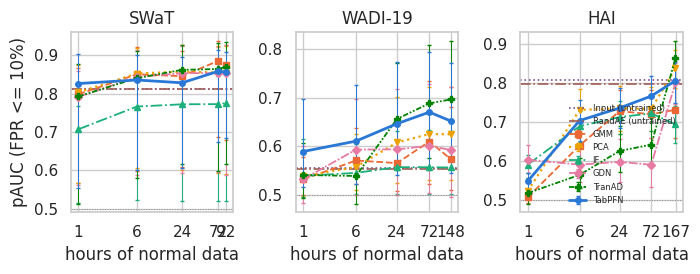

In [25]:
FAMILY_STYLE = {
    "TabPFN": {"color": "#2a78d6", "ls": "-", "marker": "o", "lw": 2.0}, "GMM": {"color": "#eb6834", "ls": "--", "marker": "s", "lw": 1.3},
    "IF": {"color": "#1baf7a", "ls": "-.", "marker": "^", "lw": 1.3}, "PCA": {"color": "#eda100", "ls": ":", "marker": "v", "lw": 1.6},
    "Input": {"color": "#7a5195", "ls": ":", "marker": "<", "lw": 1.2}, "RandAE": {"color": "#a05d56", "ls": "-.", "marker": ">", "lw": 1.2},
    "GDN": {"color": "#e87ba4", "ls": (0, (5, 1, 1, 1)), "marker": "D", "lw": 1.3}, "TranAD": {"color": "#008300", "ls": (0, (3, 1, 1, 1, 1, 1)), "marker": "P", "lw": 1.3},
}
fig, axes = plt.subplots(1, len(DS), figsize=(7.16, 2.9), sharey=False)
for ax, (name, ds) in zip(np.atleast_1d(axes), DS.items()):
    for family in E1["families"]:
        st = FAMILY_STYLE[family]
        xs, ys, lo, hi = [], [], [], []
        for bkey in list(E1["budgets_h"]) + ["full"]:
            if (name, family, bkey) not in POOL:
                continue
            p, d = POOL[(name, family, bkey)]
            xs.append(ds.n_fit / 3600 if bkey == "full" else bkey)
            ys.append(p)
            lo.append(p - ci(d)[0]); hi.append(ci(d)[1] - p)
        if not xs:
            continue
        if family in E1["untrained"]:
            ax.axhline(ys[-1], color=st["color"], ls=st["ls"], lw=st["lw"], label=f"{family} (untrained)")
        else:
            ax.errorbar(xs, ys, yerr=[lo, hi], color=st["color"], ls=st["ls"], lw=st["lw"], marker=st["marker"], ms=4, capsize=1.5, elinewidth=0.7,
                        label=family)
    ax.axhline(0.5, color="#8d8c86", lw=0.7, ls=":")
    ax.set_xscale("log")
    ax.set_xticks(E1["budgets_h"] + [round(ds.n_fit / 3600)])
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.set(xlabel="hours of normal data", title=name)
np.atleast_1d(axes)[0].set_ylabel("pAUC (FPR <= 10%)")
np.atleast_1d(axes)[-1].legend(fontsize=6, loc="lower right", frameon=False)
plt.tight_layout()
path = FIG_DIR / f"E1_fig7_pauc_vs_budget_{FIG_VERSION}.png"
fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
print("figure saved:", path)
plt.show()

## **9. Checks before trusting the results** (section 7 of the specification)

1. CAL and TEST rows are identical across all budgets: every cached run carries the hash of the CAL / TEST positions and features and `collect()` asserts it equals this session's (done in section 6).
2. Every budget window ends before the gap and holds no attack, guard or warm-up rows, and the replicates do not overlap (asserted in section 2).
3. Row counts per window are 3,600, 21,600, 86,400 and 259,200 (FIT contains no guard rows, so there is nothing to subtract).
4. The logged K (GMM), PCA components, stopping epochs and constant features are plausible: a 1-hour GMM with K = 1 is expected.
5. At full FIT every method reproduces its main-table pAUC within 0.005, except TabPFN (single seed here against three in the main table).

In [26]:
print("3. row counts")
display(SUMMARY[SUMMARY.method == SUMMARY.method.iloc[0]].groupby(["dataset", "budget_h", "rep"])["n_rows"].first().unstack("rep"))

print("4. what the fits chose (mean over replicates); K = GMM components per view, PCA = components per view")
log = RUN_LOG.copy()
log["budget"] = log["budget"].astype(str)
for col, label in [("k", "GMM K"), ("pca_components", "PCA components")]:
    sub = log[log[col].notna()][["dataset", "budget", "rep", col]]
    sub = pd.concat([sub[["dataset", "budget", "rep"]].reset_index(drop=True), pd.DataFrame(sub[col].tolist())], axis=1)
    print(label)
    display(sub.groupby(["dataset", "budget"], sort=False).mean(numeric_only=True).drop(columns="rep").round(1))
dl = log[log["family"].isin(["GDN", "TranAD"])].copy()
if len(dl):
    dl["mean_epochs"] = dl["epochs"].map(np.mean)
    print("GDN / TranAD: epochs before early stopping (mean of 3 seeds), training windows, batch size")
    display(dl.groupby(["dataset", "family", "budget"], sort=False)[["mean_epochs", "train_windows", "batch_size"]].mean().round(1))
cf = log[log["n_const_features"].notna()][["dataset", "family", "budget", "rep", "n_const_features"]]
cf = cf.assign(total=cf["n_const_features"].map(lambda d: sum(d.values())))
print("features constant inside the budget window (left unscaled), summed over views")
display(cf.groupby(["dataset", "budget"], sort=False)["total"].agg(["min", "max"]).T)

print("5. full-FIT pAUC against the main table (|difference| <= 0.005 expected, TabPFN excepted)")
MAIN_NAMES = {"TabPFN": "TabPFN fused", "GMM": "GMM fused", "IF": "IF fused", "PCA": "PCA fused", "Input": "Input fused", "RandAE": "RandAE fused",
              "GDN": "GDN", "TranAD": "TranAD"}
rows = []
for name, ds in DS.items():
    ref_path = RESULTS_ROOT / DATASETS[name]["reference"] / "results_headline.csv"
    if not ref_path.exists():
        continue
    ref = pd.read_csv(ref_path).set_index("method")["pauc"]
    for family, mname in MAIN_NAMES.items():
        if (name, family, "full") in POOL and mname in ref.index:
            rows.append({"dataset": name, "method": family, "pauc_here": POOL[(name, family, "full")][0], "pauc_main": float(ref[mname])})
chk = pd.DataFrame(rows)
if len(chk):
    chk["difference"] = chk["pauc_here"] - chk["pauc_main"]
    chk["within_0.005"] = chk["difference"].abs() <= 0.005
    display(chk.round(4))
    bad = chk[~chk["within_0.005"] & (chk["method"] != "TabPFN")]
    print("OK: every non-TabPFN method reproduces the main table" if bad.empty else f"CHECK: {len(bad)} non-TabPFN method(s) differ from the main table by more than 0.005")
    chk.to_csv(RUN_DIR / "E1_full_fit_check.csv", index=False)

3. row counts


rep                        0        1        2
dataset budget_h                              
HAI     1.000000      3600.0   3600.0   3600.0
        6.000000     21600.0  21600.0  21600.0
        24.000000    86400.0  86400.0  86400.0
        72.000000   259200.0      NaN      NaN
        166.600556  599762.0      NaN      NaN
SWaT    1.000000      3600.0   3600.0   3600.0
        6.000000     21600.0  21600.0  21600.0
        24.000000    86400.0  86400.0  86400.0
        72.000000   259200.0      NaN      NaN
        92.050000   331380.0      NaN      NaN
WADI-19 1.000000      3600.0   3600.0   3600.0
        6.000000     21600.0  21600.0  21600.0
        24.000000    86400.0  86400.0  86400.0
        72.000000   259200.0      NaN      NaN
        148.355278  534079.0      NaN      NaN

4. what the fits chose (mean over replicates); K = GMM components per view, PCA = components per view
GMM K


state  detrend  dynamics
dataset budget                          
SWaT    1         1.0      1.0       1.0
        6         1.0      4.0       4.0
        24        8.0     16.0      16.0
        72       32.0     32.0      32.0
        full     32.0     32.0      32.0
WADI-19 1         1.0      1.0       1.0
        6         1.0      1.0       1.0
        24        8.0      6.7       8.0
        72       16.0     32.0      32.0
        full    128.0     64.0      64.0
HAI     1         1.0      1.0       1.0
        6         1.0      1.0       1.0
        24        8.0      5.3       6.7
        72       16.0     16.0      16.0
        full     32.0     32.0      32.0

PCA components


state  detrend  dynamics
dataset budget                          
SWaT    1        11.3     11.0      12.0
        6        11.7     12.0      12.3
        24       10.7     12.0      12.3
        72       10.0     12.0      13.0
        full     12.0     12.0      13.0
WADI-19 1        11.3     11.3      13.7
        6        17.7     21.0      17.7
        24       21.3     23.7      18.3
        72       24.0     24.0      18.0
        full     25.0     24.0      18.0
HAI     1        16.3     19.0      20.7
        6        17.7     22.0      24.7
        24       20.0     24.0      27.0
        72       21.0     24.0      27.0
        full     21.0     24.0      27.0

... (3 outputs left out)

dataset SWaT               WADI-19               HAI              
budget     1  6 24 72 full       1  6 24 72 full   1  6 24 72 full
min        1  1  1  1    0       4  0  0  0    0   4  0  0  0    0
max        4  1  1  1    0      23  0  0  0    0  16  1  0  0    0

5. full-FIT pAUC against the main table (|difference| <= 0.005 expected, TabPFN excepted)


,dataset,method,pauc_here,pauc_main,difference,within_0.005
0,SWaT,TabPFN,0.8564,0.8557,0.0007,True
1,SWaT,GMM,0.8749,0.8749,0.0000,True
2,SWaT,IF,0.7752,0.7752,0.0000,True
3,SWaT,PCA,0.8535,0.8535,-0.0000,True
4,SWaT,Input,0.8112,0.8112,0.0000,True
5,SWaT,RandAE,0.8108,0.8108,0.0000,True
6,SWaT,GDN,0.8543,0.8543,0.0000,True
7,SWaT,TranAD,0.8702,0.8702,0.0000,True
8,WADI-19,TabPFN,0.6518,0.6616,-0.0098,False
9,WADI-19,GMM,0.5734,0.5240,0.0494,False


CHECK: 2 non-TabPFN method(s) differ from the main table by more than 0.005


## **Conclusions**

Written from `E1_summary.csv`, `E1_paired.csv`, `E1_primary_test.csv`, `E1_tabpfn_vs_full.csv` and `E1_full_fit_check.csv` (run of 25–27 Oct 2026). The detailed text for the paper is `paper-plan/new-paper/e1_data_efficiency.tex`.

**1. Primary hypothesis (6 h): supported on 3 of 6 comparisons.** D = loss(m) − loss(TabPFN), loss = pAUC(full) − pAUC(6 h); positive favours TabPFN.

| dataset | vs TranAD | vs GDN |
|---|---|---|
| SWaT | +0.009 [−0.085, +0.040] — not supported | −0.010 [−0.120, +0.020] — not supported |
| WADI-19 | **+0.116 [+0.037, +0.229]** — supported | −0.042 [−0.164, +0.073] — not supported |
| HAI | **+0.197 [+0.151, +0.242]** — supported | **+0.109 [+0.060, +0.156]** — supported |

2 of 3 against TranAD, 1 of 3 against GDN. Losses 6 h → full (pAUC): TabPFN 0.02 / 0.04 / 0.10 (SWaT / WADI-19 / HAI), TranAD 0.03 / 0.16 / 0.30, GDN 0.01 / 0.00 / 0.21. The negative D against GDN on WADI-19 is not data efficiency: GDN barely learns there (0.593 at 6 h, 0.592 at full FIT).

**2. Not specific to 6 h.** Against TranAD on WADI-19 D is supported at every budget (+0.093, +0.116, +0.035, +0.026 at 1, 6, 24, 72 h) but shrinks: TranAD overtakes TabPFN at 24 h (0.656 vs 0.646) and ends at 0.696 vs 0.652 (full FIT). On HAI D grows with the budget (TranAD +0.088 → +0.182; GDN −0.059 at 1 h, then +0.109, +0.134, +0.172): GDN is flat at ≈0.59–0.60 from 1 h to 72 h and reaches 0.80 only with the full split. On SWaT D is never in TabPFN's favour; at 24 h it is significantly against it (TranAD −0.020, GDN −0.027, PCA −0.032).

**3. Where TabPFN stops losing.** Its interval includes the full-FIT pAUC from 1 h on SWaT and WADI-19 and from 72 h on HAI (0.767 vs 0.806; 6 h and 24 h do not include it). On SWaT and WADI-19 this is weak evidence (intervals as wide as [0.56, 0.90] and [0.52, 0.70] at 1 h). Only on HAI is the TabPFN curve clearly increasing (0.548, 0.704, 0.736, 0.767, 0.806); on WADI-19 it rises slowly (0.589 → 0.670), on SWaT it is flat (0.826 → 0.858). TabPFN − method at 6 h: supported over TranAD (+0.140), GDN (+0.113) and GMM (+0.064) on HAI, and over the input norm on SWaT (+0.025) and WADI-19 (+0.081); not supported against PCA anywhere.

**4. The untrained floor.** On HAI the input norm (no fit beyond a standardisation) is above TabPFN at 6 h (0.769 vs 0.704, −0.065 [−0.110, −0.024]) and in the point estimate at 24 h; TabPFN reaches it only at 72 h (0.767 vs 0.770). GDN and TranAD stay below it up to 72 h (0.590 and 0.642 vs 0.770). On SWaT and WADI-19 TabPFN is above the input norm at every budget; TranAD sits at the untrained level up to 6 h on WADI-19 (0.541, 0.539 vs 0.539, 0.529).

**5. Operating point.** TabPFN's realised FPR (nominal 1%) stays at 1.0–2.5% on WADI-19 and 1.8–4.4% on HAI, and is 3.2–11.8% on SWaT; it grows with the budget (as in the context ablation). On HAI, from 6 h on, input norm, PCA, Random AE, GDN, TranAD and (at 72 h) GMM have a realised FPR of 29–96%, against 2–9% at full FIT; only Isolation Forest stays at 1.8–2.1%. The attacks they find at that FPR are not comparable (TranAD: 47/50 at 86% FPR vs TabPFN 31/50 at 2.4%). The static threshold therefore stays usable for TabPFN on short records and not for most other detectors on HAI. The cause was not tested; a standardisation fitted on a narrow window is a plausible mechanism.

**6. Caveats.**
- The GMM cap K ≤ ⌊n/(10 d)⌋ is specific to E1 (K = 1 at 1 h everywhere and at 6 h on WADI-19 / HAI). The full-FIT GMM does not reproduce the main table on WADI-19 (0.573 vs 0.524) and HAI (0.731 vs 0.778): do not interpret GMM losses. Every other method reproduces its main pAUC within 0.005, except TabPFN on WADI-19 (−0.010; single seed here, three in the main table).
- Six TabPFN views in three one-hour runs (WADI-19 rep 2; HAI reps 0 and 1) needed the fallback (constant features dropped, all numeric); the two HAI replicates score 0.48 and 0.49 against 0.68 for the third, so the 1 h TabPFN value on HAI is the least reliable number.
- Three replicates per budget, one at 72 h; the bootstrap resamples attacks and normal hours, not windows.
- GDN/TranAD use the main pipeline's maximum epochs, so short windows get fewer gradient steps (TranAD always 20 epochs); their slow rise mixes less data with less optimisation.
- The detrend view of the first rows of a window uses up to 10 min of earlier data; the tag list is not recomputed per budget; standard deviation 0 is set to 1 (up to 23 features at 1 h, at most 1 at 6 h and above).

**Reading.** TabPFN loses less than a trained network where the network needs data (TranAD on WADI-19, TranAD and GDN on HAI); the advantage disappears at about one day on WADI-19 and is absent on SWaT, where every detector saturates early. It is not the best detector for a new plant: on HAI an untrained norm is better at 6 h and the full-record result stays below TranAD. The supported statement is competitiveness with short records and a stable operating point, not superiority.